# Medición del *seeing* con el método DIMM
### Máscara de Hartmann sin cuña · Meade LX200 10" · ZWO ASI294MC · videos `.ser` sin seguimiento

Este notebook recibe un video `.ser` de ~15 s de una estrella vista a través de una máscara de Hartmann de dos agujeros y calcula el **seeing** con el método DIMM (*Differential Image Motion Monitor*). Para eso:

1. extrae los frames del video,
2. ubica los centroides de las dos imágenes de la estrella en cada frame (sigue la deriva, porque el telescopio no tiene seguimiento),
3. mide el **movimiento diferencial** entre ambas imágenes,
4. lo convierte en parámetro de Fried $r_0$ y en seeing (FWHM) con las fórmulas de **Tokovinin (2002)**,
5. corrige al cenit y guarda los resultados.

**Cómo usarlo**
- La primera vez déjalo con `USAR_SIMULACION = True` (sección 3). Genera un video de prueba con un seeing **conocido** (1.50″) para que veas que el método lo recupera.
- Para analizar un video real, pon `USAR_SIMULACION = False`, escribe la ruta en `RUTA_VIDEO` y ejecuta todo (*Run All*).

| Sección | Contenido |
|---|---|
| 1 | Conceptos fundamentales (con gráficas) |
| 2 | Librerías |
| 3 | Configuración del instrumento y del análisis |
| 4 | Números clave del instrumento y curva de calibración |
| 5 | Lector de archivos `.ser` |
| 6 | Video de prueba simulado |
| 7 | Abrir y explorar el video |
| 8 | Detección de las dos imágenes y diagnóstico del desenfoque |
| 9 | Centroides en todos los frames |
| 10 | Control de calidad |
| 11 | Movimiento diferencial longitudinal y transversal |
| 12 | Ruido de centroide |
| 13 | Cálculo del seeing |
| 14 | Corrección al cenit |
| 15 | Diagnóstico del tiempo de exposición |
| 16 | Resumen y guardado de resultados |
| 17 | Procesar varios videos de una noche |
| 18 | Limitaciones y recomendaciones de captura |

**Referencias** (en la carpeta del proyecto): Sarazin & Roddier 1990 · Vernin & Muñoz-Tuñón 1995 · **Tokovinin 2002** (fórmulas principales) · Tokovinin & Kornilov 2007 (sesgos) · Kornilov & Safonov 2011 (exposición) · Mammana, informe CASLEO 2024 (conceptos en español).

## 1. Conceptos fundamentales

**PSF (*Point Spread Function*).** Una estrella es, en la práctica, un punto. La imagen que de ella forma un telescopio no es un punto sino una mancha: esa mancha es la PSF. Su forma depende de la óptica (difracción) y de la atmósfera (turbulencia).

**Disco de Airy.** Aun sin atmósfera, una apertura circular de diámetro $D$ produce un patrón de difracción: un núcleo brillante rodeado de anillos. El primer anillo oscuro está a $1.22\,\lambda/D$ y el ancho a media altura es $\approx 1.03\,\lambda/D$. Es el límite de resolución del instrumento.

**FWHM (*Full Width at Half Maximum*).** Ancho de la PSF a la mitad de su altura máxima. Es la forma estándar de expresar el tamaño de una imagen estelar, y **el seeing se expresa como un FWHM en segundos de arco (″)**.

**Seeing.** Degradación de la imagen causada por la turbulencia atmosférica. Las celdas de aire con distinta temperatura tienen distinto índice de refracción y deforman el frente de onda. En una exposición larga la imagen de la estrella se ensancha hasta un FWHM típico de 0.5″–3″, mucho mayor que el disco de Airy de un telescopio grande.

**Modelo de Kolmogorov.** Describe estadísticamente la turbulencia: la diferencia de fase entre dos puntos del frente de onda separados una distancia $r$ crece como $r^{5/3}$. Con este modelo **un solo parámetro**, $r_0$, describe toda la degradación.

**Parámetro de Fried $r_0$.** Es el diámetro de un telescopio "ideal" cuya resolución por difracción igualaría la que impone la atmósfera. Cuanto mayor es $r_0$, mejor es el seeing:
$$\varepsilon = 0.98\,\frac{\lambda}{r_0}\qquad (\lambda = 500\ \text{nm por convención})$$
Por ejemplo, $r_0 = 10$ cm corresponde a $\varepsilon \approx 1.0''$ y $r_0 = 5$ cm a $\approx 2.0''$.

**Método DIMM.** Medir el FWHM directamente exige un telescopio perfecto y con seguimiento perfecto. El DIMM evita eso: una máscara con dos agujeros (diámetro $D$, separación $B$) forma **dos imágenes** de la misma estrella. La turbulencia mueve cada imagen de forma un poco distinta, mientras que las vibraciones, el viento sobre el tubo o la falta de seguimiento mueven **las dos por igual**. Midiendo solo la **diferencia** de posiciones, el movimiento común se cancela y queda la turbulencia.

**Distancia entre centroides.** El centroide es el "centro de masa" de la luz de cada imagen. La varianza $\sigma^2$ de la distancia entre los dos centroides, medida en dirección paralela a los agujeros (**longitudinal**, $l$) y perpendicular (**transversal**, $t$), se relaciona con $r_0$ (Tokovinin 2002, ec. 8):
$$\sigma^2_{l,t} = K_{l,t}\left(\frac{\lambda}{D}\right)^2\left(\frac{D}{r_0}\right)^{5/3},\qquad b = B/D$$
$$K_l = 0.364\,(1 - 0.532\,b^{-1/3} - 0.024\,b^{-7/3}),\qquad K_t = 0.364\,(1 - 0.798\,b^{-1/3} + 0.018\,b^{-7/3})$$

**Corrección al cenit.** Mirando a una altura menor, la luz cruza más atmósfera y el seeing empeora. Para comparar noches se reduce todo al cenit (ángulo cenital $z$):
$$\varepsilon_0 = \varepsilon_z\,(\cos z)^{3/5}$$

Las gráficas de abajo comparan el disco de Airy con la PSF del seeing y muestran la relación entre seeing y $r_0$.

In [5]:
# ---- 2. Librerías y estilo de las gráficas ----
import os, json, struct, time, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle
from scipy import ndimage
from scipy.special import j1, erfc

RAD2ARCSEC = 206264.806

# Colores fijos: azul = imagen A / longitudinal, naranja = imagen B / transversal
C_A, C_B = "#2a78d6", "#eb6834"
C_L, C_T = C_A, C_B
C_3, C_GRIS, C_MAL = "#1baf7a", "#8a8984", "#e34948"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9.5,
    "lines.linewidth": 1.6, "legend.frameon": False,
})
print("Librerías cargadas. numpy", np.__version__)

Librerías cargadas. numpy 2.5.2


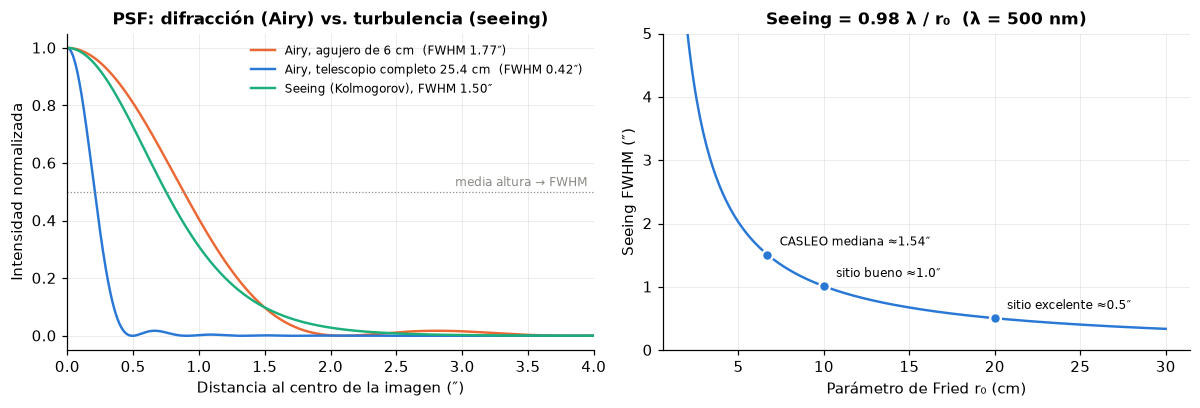

In [6]:
# ---- 1b. Gráficas de conceptos: disco de Airy vs seeing, y seeing vs r0 ----
lam = 500e-9
theta = np.linspace(1e-4, 4.0, 2000)                 # segundos de arco
def airy(theta_arcsec, D):
    x = np.pi * D * (theta_arcsec / RAD2ARCSEC) / lam
    return (2 * j1(x) / x) ** 2
def fwhm_perfil(theta, perfil):
    return 2 * theta[np.argmin(np.abs(perfil - 0.5))]

seeing_ej = 1.5                                       # seeing de ejemplo (″)
beta = 4.765                                          # Moffat ≈ PSF de Kolmogorov (Trujillo et al. 2001)
alpha = seeing_ej / (2 * np.sqrt(2 ** (1 / beta) - 1))
psf_seeing = (1 + (theta / alpha) ** 2) ** (-beta)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for D, c, nom in [(0.06, C_B, 'Airy, agujero de 6 cm'), (0.254, C_A, 'Airy, telescopio completo 25.4 cm')]:
    p = airy(theta, D)
    ax[0].plot(theta, p, color=c, label=f'{nom}  (FWHM {fwhm_perfil(theta, p):.2f}″)')
ax[0].plot(theta, psf_seeing, color=C_3, label=f'Seeing (Kolmogorov), FWHM {seeing_ej:.2f}″')
ax[0].axhline(0.5, color=C_GRIS, lw=0.8, ls=':')
ax[0].text(3.95, 0.52, 'media altura → FWHM', ha='right', color=C_GRIS, fontsize=8)
ax[0].set(xlabel='Distancia al centro de la imagen (″)', ylabel='Intensidad normalizada',
          title='PSF: difracción (Airy) vs. turbulencia (seeing)', xlim=(0, 4))
ax[0].legend(fontsize=8)

r0 = np.linspace(2, 30, 300)                          # cm
ax[1].plot(r0, 0.98 * lam / (r0 / 100) * RAD2ARCSEC, color=C_A)
for r, txt in [(6.7, 'CASLEO mediana ≈1.54″'), (10, 'sitio bueno ≈1.0″'), (20, 'sitio excelente ≈0.5″')]:
    s = 0.98 * lam / (r / 100) * RAD2ARCSEC
    ax[1].plot(r, s, 'o', ms=7, color=C_A, mec='white', mew=1.5)
    ax[1].annotate(txt, (r, s), xytext=(8, 6), textcoords='offset points', fontsize=8)
ax[1].set(xlabel='Parámetro de Fried r₀ (cm)', ylabel='Seeing FWHM (″)',
          title='Seeing = 0.98 λ / r₀  (λ = 500 nm)', ylim=(0, 5))
plt.tight_layout(); plt.show()

## 3. Configuración

Esta es la **única celda que normalmente necesitas editar**. Los valores por defecto son los de tu ficha de instrumentación.

In [7]:
# ================= VIDEO =================
USAR_SIMULACION = False                  # True: genera y analiza un video de prueba (sección 6)
RUTA_VIDEO = "2026-09-12-0050_9-U-G-Jup.ser"    # tu video real (cuando USAR_SIMULACION = False)
CARPETA_RESULTADOS = "resultados_seeing"

# ================= TELESCOPIO Y MÁSCARA =================
FOCAL_MM = 2500.0          # Meade LX200 10" f/10
D_AGUJERO_M = 0.060        # diámetro de cada agujero de la máscara (D)
B_SEPARACION_M = 0.175     # distancia entre centros de los agujeros (B)

# ================= CÁMARA (ZWO ASI294MC) =================
PIXEL_UM = 4.63            # tamaño de píxel
BINNING_CAPTURA = 1        # binning usado en FireCapture (1 si no usaste)
MODO_COLOR = "superpixel"  # cámara a color: "superpixel" suma cada bloque Bayer 2x2 (recomendado)
                           #                 "crudo" usa los píxeles Bayer tal cual
GANANCIA_E_POR_ADU = 1.0   # electrones por ADU (línea 'eADU' del .txt de FireCapture; se lee sola si está el .txt)
EXPOSICION_MS = 5.0        # exposición (si junto al .ser está el .txt de FireCapture, se lee de ahí)
FPS_SI_NO_HAY_TIEMPOS = 57.0  # solo si el .ser no trae marcas de tiempo por frame

# ================= OBSERVACIÓN =================
LAMBDA_M = 500e-9          # longitud de onda estándar para expresar el seeing (Tokovinin 2002)
ALTITUD_DEG = 32.47         # altura de la estrella sobre el horizonte (de Stellarium, p.ej.). None = calcularla
# Para calcular la altura automáticamente con la hora del video:
NOMBRE_ESTRELLA = "Alphecca"
ESTRELLA_AR_HORAS = 15.5780   # ascensión recta J2000 en horas decimales (p.ej. Vega = 18.6156)
ESTRELLA_DEC_DEG = 26.7181      # declinación J2000 en grados (p.ej. Vega = 38.7837)
SITIO_LAT_DEG = 4.6609       # latitud del sitio (+ norte)
SITIO_LON_DEG = -74.0596       # longitud del sitio (+ este, − oeste; Colombia ≈ −74)

# ================= ANÁLISIS =================
N_SIGMA_DETECCION = 5.0    # umbral de detección de las imágenes (en sigmas del ruido de fondo)
RADIO_VENTANA_PX = None    # radio de la ventana de centroide; None = automático
MARGEN_BUSQUEDA_PX = 40    # cuánto puede saltar la pareja de imágenes entre frames (empujones manuales)
FLUJO_MIN_REL = 0.30       # descarta frames con flujo < 30 % de la mediana (nubes, estrella saliendo)
CORTE_ATIPICOS_SIGMA = 5.0 # descarta frames con movimiento diferencial > 5σ (golpes, rayos cósmicos)
TAMANO_BLOQUE = 200        # frames por bloque para ver la estabilidad del seeing dentro del video

## 4. Números clave del instrumento

**Escala de placa.** Indica cuántos segundos de arco del cielo caben en un píxel:
$$\text{escala} = 206265\,\frac{\text{tamaño de píxel}}{\text{distancia focal}}$$

**Cámara a color.** La ASI294MC tiene una matriz Bayer (filtros RGGB). En modo `superpixel` cada bloque de 2×2 píxeles se suma en uno solo. Eso elimina el patrón de colores, que distorsionaría el centroide. La escala efectiva se duplica, pero sigue muestreando bien la imagen.

**Curva de calibración.** La gráfica muestra cuánto se mueven las imágenes (desviación estándar del movimiento diferencial) para cada valor de seeing con *tu* máscara. Sirve para saber qué esperar: si el seeing es 1.5″, la distancia entre centroides fluctúa unas décimas de segundo de arco, alrededor de un píxel.

b = B/D = 2.92  →  OK (B ≥ 2D)
K_l = 0.2277   K_t = 0.1612   cociente teórico σ²_l/σ²_t = 1.41
Escala de placa nativa: 0.382 ″/px  (superpixel 2x2: 0.764 ″/px)
Difracción de cada agujero λ/D = 1.72″,  primer anillo oscuro 1.22λ/D = 2.10″
Obstrucción central: agujeros entre 5.8 y 11.8 cm del eje (el secundario del LX200 10" cubre ~4.7 cm de radio)


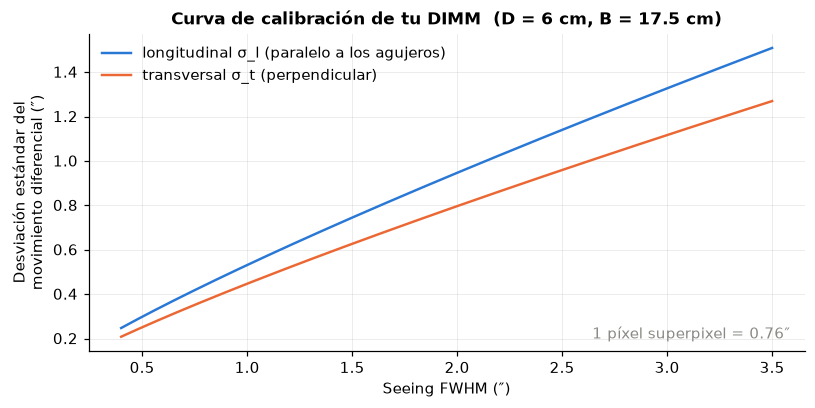

In [8]:
def coeficientes_tokovinin(b):
    # K_l, K_t para inclinación de Zernike (Tokovinin 2002, ec. 8). b = B/D
    Kl = 0.364 * (1 - 0.532 * b ** (-1/3) - 0.024 * b ** (-7/3))
    Kt = 0.364 * (1 - 0.798 * b ** (-1/3) + 0.018 * b ** (-7/3))
    return Kl, Kt

def coeficientes_sarazin_roddier(b):
    # Fórmulas clásicas de Sarazin & Roddier 1990 (Tokovinin 2002, ec. 6), solo para comparar
    return 0.358 * (1 - 0.541 * b ** (-1/3)), 0.358 * (1 - 0.810 * b ** (-1/3))

def sigma_diferencial_arcsec(seeing_arcsec, K, D=D_AGUJERO_M, lam=LAMBDA_M):
    r0 = 0.98 * lam / (np.asarray(seeing_arcsec) / RAD2ARCSEC)
    return np.sqrt(K * (lam / D) ** 2 * (D / r0) ** (5/3)) * RAD2ARCSEC

def r0_desde_varianza(var_rad2, K, D=D_AGUJERO_M, lam=LAMBDA_M):
    return D * (K * (lam / D) ** 2 / var_rad2) ** (3/5)

def seeing_desde_r0(r0, lam=LAMBDA_M):
    return 0.98 * lam / r0 * RAD2ARCSEC

b = B_SEPARACION_M / D_AGUJERO_M
KL, KT = coeficientes_tokovinin(b)
ESCALA_NATIVA = RAD2ARCSEC * PIXEL_UM * 1e-6 * BINNING_CAPTURA / (FOCAL_MM * 1e-3)   # ″/px
LAMBDA_D_ARCSEC = LAMBDA_M / D_AGUJERO_M * RAD2ARCSEC

print(f"b = B/D = {b:.2f}  →  {'OK (B ≥ 2D)' if b >= 2 else 'ATENCIÓN: B < 2D, las fórmulas pierden validez'}")
print(f"K_l = {KL:.4f}   K_t = {KT:.4f}   cociente teórico σ²_l/σ²_t = {KL/KT:.2f}")
print(f"Escala de placa nativa: {ESCALA_NATIVA:.3f} ″/px  (superpixel 2x2: {2*ESCALA_NATIVA:.3f} ″/px)")
print(f"Difracción de cada agujero λ/D = {LAMBDA_D_ARCSEC:.2f}″,  primer anillo oscuro 1.22λ/D = {1.22*LAMBDA_D_ARCSEC:.2f}″")
print(f"Obstrucción central: agujeros entre {100*(B_SEPARACION_M-D_AGUJERO_M)/2:.1f} y "
      f"{100*(B_SEPARACION_M+D_AGUJERO_M)/2:.1f} cm del eje (el secundario del LX200 10\" cubre ~4.7 cm de radio)")

s = np.linspace(0.4, 3.5, 200)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(s, sigma_diferencial_arcsec(s, KL), color=C_L, label='longitudinal σ_l (paralelo a los agujeros)')
ax.plot(s, sigma_diferencial_arcsec(s, KT), color=C_T, label='transversal σ_t (perpendicular)')
ax.set(xlabel='Seeing FWHM (″)', ylabel='Desviación estándar del\nmovimiento diferencial (″)',
       title=f'Curva de calibración de tu DIMM  (D = {D_AGUJERO_M*100:.0f} cm, B = {B_SEPARACION_M*100:.1f} cm)')
ax.legend(loc='upper left')
ax.text(0.98, 0.04, f'1 píxel superpixel = {2*ESCALA_NATIVA:.2f}″', transform=ax.transAxes, ha='right', color=C_GRIS)
plt.tight_layout(); plt.show()

## 5. Lector de archivos `.ser`

El formato SER (usado por FireCapture y SharpCap) es sencillo:
- una **cabecera de 178 bytes** (tamaño de imagen, bits por píxel, tipo de color, número de frames, fecha),
- los **frames** uno tras otro, sin compresión,
- al final, opcionalmente, una **marca de tiempo UTC por frame**.

El lector usa `np.memmap`: no carga el video completo en memoria sino que lee cada frame cuando se necesita, y solo el recorte alrededor de la estrella. Así funciona aunque el video ocupe varios GB.

> Detalle técnico: la bandera de *endianness* de la cabecera está invertida en muchos programas. Por eso el lector detecta el orden de bytes mirando los datos.

In [9]:
class LectorSER:
    BAYER = {8: 'RGGB', 9: 'GRBG', 10: 'GBRG', 11: 'BGGR', 16: 'CYYM', 17: 'YCMY', 18: 'YMCY', 19: 'MYYC'}

    def __init__(self, ruta, modo_color=MODO_COLOR):
        self.ruta = str(ruta)
        with open(self.ruta, 'rb') as f:
            h = f.read(178)
        if len(h) < 178:
            raise ValueError("El archivo es demasiado corto para ser un .ser")
        self.file_id = h[:14].decode('latin-1')
        (self.lu_id, self.color_id, self.flag_endian, self.ancho_crudo, self.alto_crudo,
         self.bits, self.n_frames) = struct.unpack('<7i', h[14:42])
        txt = lambda bb: bb.decode('latin-1').replace('\x00', '').strip()
        self.observador, self.instrumento, self.telescopio = txt(h[42:82]), txt(h[82:122]), txt(h[122:162])
        self.ticks_local, self.ticks_utc = struct.unpack('<2q', h[162:178])

        self.planos = 3 if self.color_id in (100, 101) else 1
        self.bytes_px = 1 if self.bits <= 8 else 2
        self.es_bayer = self.color_id in self.BAYER
        self.k = 2 if (self.es_bayer and modo_color == 'superpixel') else 1   # factor de reducción
        bytes_frame = self.ancho_crudo * self.alto_crudo * self.planos * self.bytes_px
        tam = os.path.getsize(self.ruta)
        n_posibles = (tam - 178) // bytes_frame
        if n_posibles < self.n_frames:
            print(f"Aviso: la cabecera dice {self.n_frames} frames pero el archivo solo contiene {n_posibles}")
            self.n_frames = int(n_posibles)

        forma = (self.n_frames, self.alto_crudo, self.ancho_crudo) + ((3,) if self.planos == 3 else ())
        if self.bytes_px == 1:
            self.mm = np.memmap(self.ruta, dtype=np.uint8, mode='r', offset=178, shape=forma)
            self.endian = 'n/a (8 bits)'
        else:
            self.endian = self._detectar_endian(forma)
            self.mm = np.memmap(self.ruta, dtype=self.endian + 'u2', mode='r', offset=178, shape=forma)

        # Nivel de saturación de un píxel crudo
        self.saturacion = 2 ** self.bits - 1 if self.bits <= 16 else 65535
        if self.bytes_px == 2 and self.mm[self.n_frames // 2].max() > self.saturacion:
            self.saturacion = 65535     # datos de 12/14 bits alineados a 16

        # Marcas de tiempo por frame (ticks de 100 ns desde el año 1)
        fin = 178 + self.n_frames * bytes_frame
        self.ticks_frames = None
        if tam >= fin + 8 * self.n_frames:
            ts = np.fromfile(self.ruta, dtype='<i8', count=self.n_frames, offset=fin)
            if np.all(np.diff(ts) >= 0) and ts[-1] > ts[0]:   # FireCapture repite algunas marcas (resolución 1 ms)
                self.ticks_frames = ts
        if self.ticks_frames is not None:
            self.tiempos = (self.ticks_frames - self.ticks_frames[0]) * 1e-7
        else:
            self.tiempos = np.arange(self.n_frames) / FPS_SI_NO_HAY_TIEMPOS

        self.alto = self.alto_crudo // self.k
        self.ancho = self.ancho_crudo // self.k

    def _detectar_endian(self, forma):
        # El orden correcto produce una imagen suave; el incorrecto, ruido enorme entre píxeles vecinos
        res = {}
        for e in ('<', '>'):
            m = np.memmap(self.ruta, dtype=e + 'u2', mode='r', offset=178, shape=forma)
            fr = np.asarray(m[self.n_frames // 2][::4, ::4], dtype=np.float64)
            res[e] = np.mean(np.abs(np.diff(fr, axis=-1)))
            del m
        return min(res, key=res.get)

    @staticmethod
    def ticks_a_fecha(ticks):
        if ticks is None or ticks <= 0:
            return None
        return dt.datetime(1, 1, 1) + dt.timedelta(microseconds=int(ticks) // 10)

    @property
    def fecha_utc(self):
        if self.ticks_frames is not None:
            return self.ticks_a_fecha(self.ticks_frames[self.n_frames // 2])
        return self.ticks_a_fecha(self.ticks_utc)

    def leer(self, i, recorte=None):
        # Devuelve el frame i (o un recorte y0, y1, x0, x1 en coordenadas procesadas) en float32
        k = self.k
        if recorte is None:
            f = self.mm[i]
        else:
            y0, y1, x0, x1 = recorte
            f = self.mm[i, y0 * k:y1 * k, x0 * k:x1 * k]
        f = np.asarray(f, dtype=np.float32)
        if self.planos == 3:
            f = f.sum(axis=-1)
        if k == 2:
            h, w = (f.shape[0] // 2) * 2, (f.shape[1] // 2) * 2
            f = f[0:h:2, 0:w:2] + f[1:h:2, 0:w:2] + f[0:h:2, 1:w:2] + f[1:h:2, 1:w:2]
        return f

    def pico_crudo(self, i, x, y, r):
        # Valor máximo de los píxeles crudos alrededor de (x, y) — para detectar saturación
        k = self.k
        x0, x1 = max(int((x - r) * k), 0), min(int((x + r + 1) * k), self.ancho_crudo)
        y0, y1 = max(int((y - r) * k), 0), min(int((y + r + 1) * k), self.alto_crudo)
        return int(np.asarray(self.mm[i, y0:y1, x0:x1]).max())

    def resumen(self):
        tipo = {0: 'MONO', 100: 'RGB', 101: 'BGR'}.get(self.color_id, self.BAYER.get(self.color_id, str(self.color_id)))
        dur = self.tiempos[-1] - self.tiempos[0]
        return {
            'archivo': Path(self.ruta).name, 'frames': self.n_frames,
            'tamaño crudo (px)': f'{self.ancho_crudo} x {self.alto_crudo}',
            'tamaño procesado (px)': f'{self.ancho} x {self.alto}' + (' (superpixel 2x2)' if self.k == 2 else ''),
            'color': tipo, 'bits': self.bits, 'orden de bytes': self.endian,
            'duración (s)': round(dur, 2), 'fps': round((self.n_frames - 1) / dur, 1) if dur > 0 else None,
            'marcas de tiempo': 'sí' if self.ticks_frames is not None else 'no (se usa FPS_SI_NO_HAY_TIEMPOS)',
            'fecha UTC': str(self.fecha_utc), 'cámara': self.instrumento, 'telescopio': self.telescopio,
        }

print("Lector SER listo.")

Lector SER listo.


## 7. Abrir y explorar el video

Primero se mira el video: la información de la cabecera, un frame completo, un acercamiento a las dos imágenes y un perfil de intensidad que pasa por ambas. Las dos imágenes deben verse **claramente separadas** y **sin saturar**.

In [11]:
def leer_txt_firecapture(ruta_ser):
    # Lee el .txt que FireCapture guarda junto al .ser y actualiza exposición y ganancia (e-/ADU)
    global EXPOSICION_MS, GANANCIA_E_POR_ADU
    txt = Path(ruta_ser).with_suffix('.txt')
    if not txt.exists():
        print(f"(no hay {txt.name}: se usan EXPOSICION_MS y GANANCIA_E_POR_ADU de la sección 3)")
        return {}
    datos = {}
    for linea in txt.read_text(encoding='latin-1').splitlines():
        if '=' in linea and not linea.startswith('Frame'):
            k_, v_ = linea.split('=', 1); datos[k_.strip()] = v_.strip()
    if 'Shutter' in datos:
        EXPOSICION_MS = float(datos['Shutter'].replace('ms', '').replace(',', '.'))
    if datos.get('eADU', 'n/a') not in ('n/a', ''):
        GANANCIA_E_POR_ADU = float(datos['eADU'].replace(',', '.'))
    print(f"Leído {txt.name}: exposición {EXPOSICION_MS} ms, ganancia {datos.get('Gain', '?')} → "
          f"{GANANCIA_E_POR_ADU} e-/ADU, {datos.get('Bit depth', '?')}, ROI {datos.get('ROI', '?')}")
    return datos

if not USAR_SIMULACION:
    TXT_FC = leer_txt_firecapture(RUTA_VIDEO)
lector = LectorSER(RUTA_VIDEO)
ESCALA = ESCALA_NATIVA * lector.k              # ″ por píxel procesado
CARPETA = Path(CARPETA_RESULTADOS) / Path(RUTA_VIDEO).stem
(CARPETA / 'figuras').mkdir(parents=True, exist_ok=True)

def guardar(fig, nombre):
    fig.savefig(CARPETA / 'figuras' / f'{nombre}.png', dpi=130, bbox_inches='tight')

display(pd.Series(lector.resumen(), name='valor').to_frame())
print(f"Escala usada en el análisis: {ESCALA:.3f} ″/px")

Leído 2026-09-12-0050_9-U-G-Jup.txt: exposición 10.0 ms, ganancia 570 (100%) → 0.399 e-/ADU, 8bit, ROI 4144x2822


,valor
archivo,2026-09-12-0050_9-U-G-Jup.ser
frames,271
tamaño crudo (px),4144 x 2822
tamaño procesado (px),2072 x 1411 (superpixel 2x2)
color,RGGB
bits,8
orden de bytes,n/a (8 bits)
duración (s),20.77
fps,13.0
marcas de tiempo,sí


Escala usada en el análisis: 0.764 ″/px


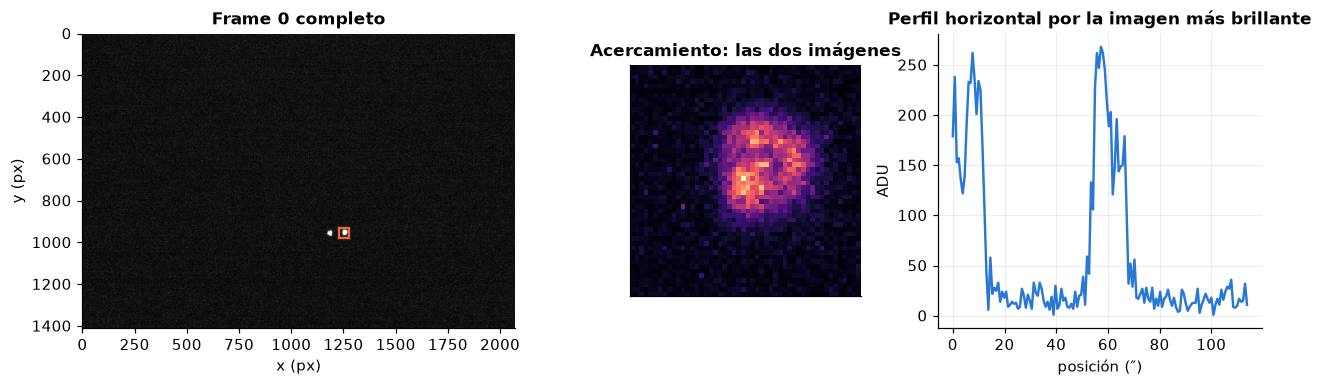

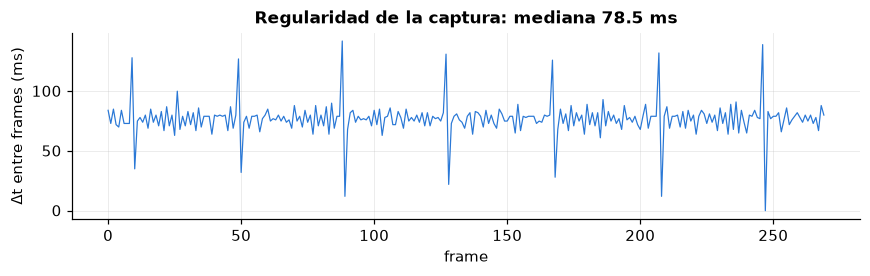

In [12]:
f0 = lector.leer(0)
fondo0 = np.median(f0)
iy, ix = np.unravel_index(np.argmax(ndimage.gaussian_filter(f0, 2)), f0.shape)
z = 25
zoom = f0[max(iy - z, 0):iy + z, max(ix - z, 0):ix + z]

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), gridspec_kw={'width_ratios': [2.2, 1, 1.4]})
vmax = np.percentile(f0, 99.9)
ax[0].imshow(f0, cmap='gray', vmin=fondo0, vmax=vmax, origin='upper')
ax[0].add_patch(Rectangle((ix - z, iy - z), 2 * z, 2 * z, fill=False, ec=C_B, lw=1.5))
ax[0].set(title='Frame 0 completo', xlabel='x (px)', ylabel='y (px)'); ax[0].grid(False)
ax[1].imshow(zoom, cmap='magma', origin='upper'); ax[1].grid(False)
ax[1].set(title='Acercamiento: las dos imágenes', xticks=[], yticks=[])
fila = f0[iy, max(ix - 3 * z, 0):ix + 3 * z]
ax[2].plot(np.arange(fila.size) * ESCALA, fila, color=C_A)
ax[2].set(title='Perfil horizontal por la imagen más brillante', xlabel='posición (″)', ylabel='ADU')
plt.tight_layout(); guardar(fig, '01_frame_inicial'); plt.show()

if lector.ticks_frames is not None:
    dtf = np.diff(lector.tiempos) * 1000
    fig, ax = plt.subplots(figsize=(8, 2.6))
    ax.plot(dtf, color=C_A, lw=0.8)
    ax.set(xlabel='frame', ylabel='Δt entre frames (ms)', title=f'Regularidad de la captura: mediana {np.median(dtf):.1f} ms')
    plt.tight_layout(); guardar(fig, '02_tiempos'); plt.show()

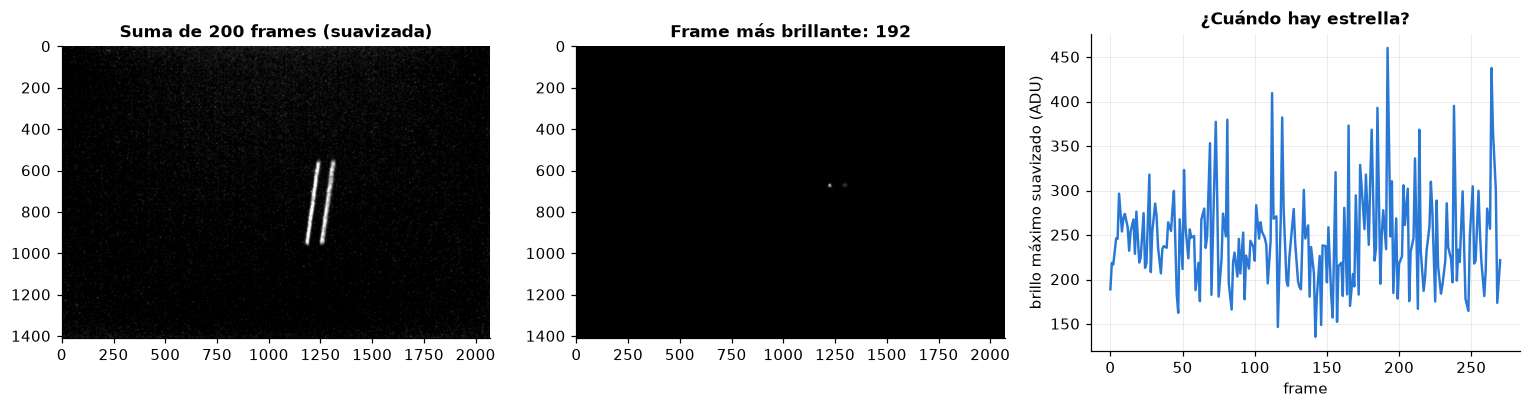

Brillo máximo suavizado: mínimo 135.7, mediana 237.7, máximo 460.3 ADU


In [13]:
# Diagnóstico: ¿en qué frames y en qué lugar aparece la estrella?
N = lector.n_frames
idx = np.linspace(0, N - 1, min(N, 200)).astype(int)
suma = np.zeros((lector.alto, lector.ancho))
senal = []
for i in idx:
    f = lector.leer(i)
    f = f - np.median(f)
    suma += f
    senal.append(ndimage.gaussian_filter(f, 3).max())   # el suavizado borra los píxeles calientes
senal = np.array(senal)
i_mejor = idx[np.argmax(senal)]
mejor = ndimage.gaussian_filter(lector.leer(i_mejor) - np.median(lector.leer(i_mejor)), 2)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
s = ndimage.gaussian_filter(suma, 2)
ax[0].imshow(s, cmap='gray', vmin=np.percentile(s, 50), vmax=np.percentile(s, 99.9)); ax[0].grid(False)
ax[0].set_title('Suma de 200 frames (suavizada)')
ax[1].imshow(mejor, cmap='gray', vmin=0, vmax=max(mejor.max(), 1)); ax[1].grid(False)
ax[1].set_title(f'Frame más brillante: {i_mejor}')
ax[2].plot(idx, senal, color=C_A)
ax[2].set(xlabel='frame', ylabel='brillo máximo suavizado (ADU)', title='¿Cuándo hay estrella?')
plt.tight_layout(); plt.show()
print(f"Brillo máximo suavizado: mínimo {senal.min():.1f}, mediana {np.median(senal):.1f}, máximo {senal.max():.1f} ADU")

## 8. Detección de las dos imágenes y diagnóstico del desenfoque

**Detección.** Se resta el fondo de cielo, se suaviza un poco la imagen y se buscan regiones por encima de `N_SIGMA_DETECCION` veces el ruido. Las dos regiones con más luz y la separación esperada son las imágenes A y B. Se llama **A** a la de la izquierda.

**Centroide con ventana (Tokovinin 2002, ec. 3).** El centroide se calcula con los píxeles dentro de un círculo de radio $R$ alrededor de cada imagen y se itera recentrando:
$$x_c = \frac{\sum x_i I_i}{\sum I_i}$$
Una ventana chica tiene poco ruido, pero corta la imagen. Tokovinin & Kornilov (2007) recomiendan un radio ≳ 2.5 λ/D para que el resultado sea estable. La ventana tampoco puede invadir la otra imagen.

**Desenfoque sin cuña.** Sin prisma, las dos imágenes coinciden en el foco y solo se separan al desenfocar. La geometría fija la relación:
$$\text{separación en el sensor } s = \Delta z\,\frac{B}{F}\quad\Rightarrow\quad a_4\,[\text{rad rms}] = \frac{2\pi}{\lambda}\,\frac{s\,D^2}{16\sqrt{3}\,B\,F}$$
Tokovinin & Kornilov (2007) muestran que un desenfoque $a_4 > 0.8$ rad **siempre sobreestima el seeing**. Por eso conviene desenfocar lo justo para separar las imágenes.

c:\Users\USUARIO\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\scipy\ndimage\_measurements.py:1550: RuntimeWarning: invalid value encountered in divide
  results = [sum_labels(input * grids[dir].astype(float), labels, index) / normalizer


Imágenes encontradas en el frame 0
  separación A–B     : 71.2 px = 54.4″   (ángulo de la línea -3.3°)
  radio rms imagen   : 12.69 px = 9.69″
  ventana centroide  : R = 31.71 px = 24.23″ = 14.1 λ/D
  desenfoque         : Δz ≈ 9.41 mm,  a4 ≈ 2.46 rad rms  ⚠ > 0.8 rad: el seeing saldrá sobreestimado (Tokovinin & Kornilov 2007). Reduce el desenfoque.


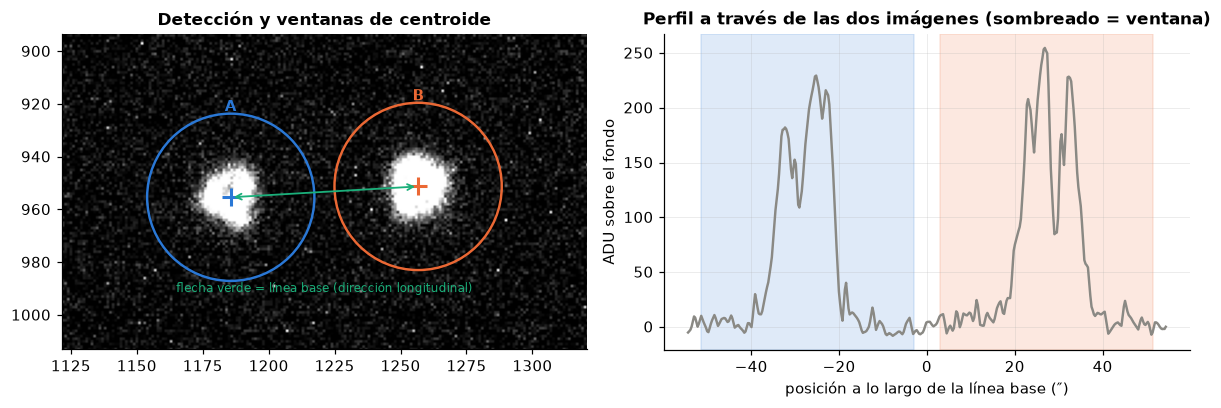

In [14]:
def estimar_fondo(img):
    sub = img if img.size < 200_000 else img[::4, ::4]
    med = float(np.median(sub))
    mad = float(np.median(np.abs(sub - med))) * 1.4826
    if mad < 0.5:                                  # datos de 8 bits con muy poco ruido
        mad = max(float(np.std(sub[sub <= med + 5])), 0.5)
    return med, mad

def detectar_manchas(img, n_sigma=N_SIGMA_DETECCION, sigma_suav=1.5, area_min=3, sep=None):
    # Busca las imágenes de la estrella. Sin 'sep': regiones conectadas (primer frame).
    # Con 'sep' (separación conocida): máximos locales, que separa bien las imágenes aunque se acerquen.
    fondo, ruido = estimar_fondo(img)
    res = img - fondo
    sm = ndimage.gaussian_filter(res, sigma_suav)
    umbral = n_sigma * ruido / (2 * np.sqrt(np.pi) * sigma_suav)   # el suavizado reduce el ruido
    if sep is not None:
        tam = max(3, int(0.6 * sep))
        picos = (sm == ndimage.maximum_filter(sm, size=tam)) & (sm > umbral)
        ys, xs = np.nonzero(picos)
        orden = np.argsort(-sm[ys, xs])[:12]
        r = 0.4 * sep
        manchas = []
        for y, x in zip(ys[orden], xs[orden]):
            if any(np.hypot(x - m['x'], y - m['y']) < tam / 2 for m in manchas):
                continue                                          # meseta: mismo máximo repetido
            ya, yb = max(int(y - r), 0), min(int(y + r) + 1, res.shape[0])
            xa, xb = max(int(x - r), 0), min(int(x + r) + 1, res.shape[1])
            yy, xx = np.mgrid[ya:yb, xa:xb]
            sub = res[ya:yb, xa:xb]
            dentro = (xx - x) ** 2 + (yy - y) ** 2 <= r * r
            manchas.append(dict(x=float(x), y=float(y), flujo=float(sub[dentro].sum()), area=int(dentro.sum())))
        manchas.sort(key=lambda m: -m['flujo'])
        return manchas, fondo, ruido
    mascara = sm > umbral
    lab, n = ndimage.label(mascara)
    if n == 0:
        return [], fondo, ruido
    idx = np.arange(1, n + 1)
    flujo = np.atleast_1d(ndimage.sum(res, lab, idx))
    area = np.atleast_1d(ndimage.sum(mascara, lab, idx))
    cms = ndimage.center_of_mass(np.clip(res, 0, None), lab, idx)
    manchas = [dict(x=c[1], y=c[0], flujo=float(f), area=int(a))
               for c, f, a in zip(cms, flujo, area) if a >= area_min]
    manchas.sort(key=lambda m: -m['flujo'])
    return manchas, fondo, ruido

def centroide_ventana(res, x0, y0, R, ruido, ganancia=None, iteraciones=5):
    # Centroide dentro de un círculo de radio R + su varianza de ruido (Tokovinin 2002, ec. 9 + fotones)
    H, W = res.shape
    for _ in range(iteraciones):
        xa, xb = int(np.floor(x0 - R)), int(np.ceil(x0 + R)) + 1
        ya, yb = int(np.floor(y0 - R)), int(np.ceil(y0 + R)) + 1
        if xa < 0 or ya < 0 or xb > W or yb > H:
            return None                                       # la ventana toca el borde
        sub = res[ya:yb, xa:xb]
        yy, xx = np.mgrid[ya:yb, xa:xb]
        dentro = (xx - x0) ** 2 + (yy - y0) ** 2 <= R * R
        I = np.where(dentro, sub, 0.0)
        F = I.sum()
        if F <= 0:
            return None
        xn, yn = (I * xx).sum() / F, (I * yy).sum() / F
        listo = abs(xn - x0) < 1e-3 and abs(yn - y0) < 1e-3
        x0, y0 = xn, yn
        if listo:
            break
    ganancia = ganancia or GANANCIA_E_POR_ADU
    var_px = ruido ** 2 + np.clip(sub, 0, None) / ganancia           # ruido de fondo+lectura y de fotones
    vx = float((dentro * (xx - x0) ** 2 * var_px).sum() / F ** 2)
    vy = float((dentro * (yy - y0) ** 2 * var_px).sum() / F ** 2)
    return dict(x=float(x0), y=float(y0), flujo=float(F), var_x=vx, var_y=vy)

def tamano_mancha(res, x0, y0, rmax):
    # radio rms de la imagen: sqrt(<r²>)
    yy, xx = np.mgrid[0:res.shape[0], 0:res.shape[1]]
    r2 = (xx - x0) ** 2 + (yy - y0) ** 2
    I = np.where(r2 <= rmax ** 2, np.clip(res, 0, None), 0)
    return float(np.sqrt((I * r2).sum() / I.sum()))

def inicializar(lector, n_prueba=40):
    for i in range(min(n_prueba, lector.n_frames)):
        img = lector.leer(i)
        manchas, fondo, ruido = detectar_manchas(img)
        if len(manchas) >= 2 and manchas[1]['flujo'] > 0.25 * manchas[0]['flujo']:
            m1, m2 = manchas[:2]
            horizontal = abs(m2['x'] - m1['x']) >= abs(m2['y'] - m1['y'])
            A, B = sorted([m1, m2], key=lambda m: m['x'] if horizontal else m['y'])
            dx, dy = B['x'] - A['x'], B['y'] - A['y']
            sep = float(np.hypot(dx, dy))
            res = img - fondo
            rms = np.mean([tamano_mancha(res, m['x'], m['y'], 0.45 * sep) for m in (A, B)])
            return dict(frame=i, A=(A['x'], A['y']), B=(B['x'], B['y']), sep_px=sep,
                        u=np.array([dx, dy]) / sep, centro=((A['x'] + B['x']) / 2, (A['y'] + B['y']) / 2),
                        rms_px=float(rms), fondo=fondo, ruido=ruido, img=img)
        if len(manchas) == 1 and manchas[0]['area'] > 50:
            print(f"Frame {i}: solo una mancha grande → ¿las dos imágenes se tocan? Desenfoca un poco más.")
    raise RuntimeError("No se encontraron dos imágenes de la estrella en los primeros frames. "
                       "Revisa el enfoque, la exposición o N_SIGMA_DETECCION.")

def desenfoque_rad(sep_px, k=1):
    s = sep_px * k * PIXEL_UM * 1e-6 * BINNING_CAPTURA            # separación física en el sensor (m)
    F = FOCAL_MM * 1e-3
    dz = s * F / B_SEPARACION_M
    a4 = 2 * np.pi / LAMBDA_M * s * D_AGUJERO_M ** 2 / (16 * np.sqrt(3) * B_SEPARACION_M * F)
    return a4, dz

ini = inicializar(lector)
lamD_px = LAMBDA_D_ARCSEC / ESCALA
R_auto = min(0.45 * ini['sep_px'], max(2.5 * lamD_px, 2.5 * ini['rms_px']))
R_VENT = RADIO_VENTANA_PX if RADIO_VENTANA_PX else R_auto
a4, dz = desenfoque_rad(ini['sep_px'], lector.k)
angulo = np.degrees(np.arctan2(ini['u'][1], ini['u'][0]))

print(f"Imágenes encontradas en el frame {ini['frame']}")
print(f"  separación A–B     : {ini['sep_px']:.1f} px = {ini['sep_px']*ESCALA:.1f}″   (ángulo de la línea {angulo:+.1f}°)")
print(f"  radio rms imagen   : {ini['rms_px']:.2f} px = {ini['rms_px']*ESCALA:.2f}″")
print(f"  ventana centroide  : R = {R_VENT:.2f} px = {R_VENT*ESCALA:.2f}″ = {R_VENT/lamD_px:.1f} λ/D")
print(f"  desenfoque         : Δz ≈ {dz*1000:.2f} mm,  a4 ≈ {a4:.2f} rad rms", end='  ')
print("✔ moderado" if a4 <= 0.8 else "⚠ > 0.8 rad: el seeing saldrá sobreestimado (Tokovinin & Kornilov 2007). Reduce el desenfoque.")
if abs(angulo) > 20 and abs(abs(angulo) - 180) > 20:
    print("  ⚠ Las imágenes no están en la misma fila: con rolling shutter conviene girar la máscara para que queden horizontales.")
if R_VENT >= 0.45 * ini['sep_px'] - 0.01:
    print("  ⚠ La ventana quedó limitada por la separación: las imágenes están muy juntas.")

img, res0 = ini['img'], ini['img'] - ini['fondo']
cx, cy = ini['centro']; w = ini['sep_px'] * 1.4
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].imshow(res0, cmap='gray', vmin=0, vmax=np.percentile(res0, 99.95), origin='upper'); ax[0].grid(False)
ax[0].set(xlim=(cx - w, cx + w), ylim=(cy + w * 0.6, cy - w * 0.6), title='Detección y ventanas de centroide')
for (x, y), c, n in [(ini['A'], C_A, 'A'), (ini['B'], C_B, 'B')]:
    ax[0].add_patch(Circle((x, y), R_VENT, fill=False, ec=c, lw=1.6))
    ax[0].plot(x, y, '+', color=c, ms=12, mew=2); ax[0].text(x, y - R_VENT - 1, n, color=c, ha='center', fontweight='bold')
ax[0].annotate('', ini['B'], ini['A'], arrowprops=dict(arrowstyle='<->', color=C_3, lw=1.2))
ax[0].text(cx, cy + R_VENT + 2.5, 'flecha verde = línea base (dirección longitudinal)', color=C_3, ha='center', va='top', fontsize=8)

# perfil a lo largo de la línea base
sgrid = np.linspace(-ini['sep_px'], ini['sep_px'], 400)
xs, ys = cx + sgrid * ini['u'][0], cy + sgrid * ini['u'][1]
perfil = ndimage.map_coordinates(res0, [ys, xs], order=1)
ax[1].plot(sgrid * ESCALA, perfil, color=C_GRIS)
for s0, c in [(-ini['sep_px'] / 2, C_A), (ini['sep_px'] / 2, C_B)]:
    ax[1].axvspan((s0 - R_VENT) * ESCALA, (s0 + R_VENT) * ESCALA, color=c, alpha=0.15)
ax[1].set(xlabel='posición a lo largo de la línea base (″)', ylabel='ADU sobre el fondo',
          title='Perfil a través de las dos imágenes (sombreado = ventana)')
plt.tight_layout(); guardar(fig, '03_deteccion'); plt.show()

## 9. Centroides en todos los frames

Como el telescopio no sigue a la estrella, la pareja de imágenes **se desplaza** por el campo. En cada frame se busca solo en un recorte alrededor de la posición anterior, lo que es rápido. Si la pareja se pierde, por ejemplo tras un empujón grande, se busca en el frame completo.

Las gráficas muestran que **A y B se mueven casi idénticamente**: ese es el movimiento común (deriva, empujones, vibración) que el DIMM elimina al restar las posiciones.

In [15]:
def elegir_par(manchas, sep, tol=0.35):
    cand = manchas[:6]
    mejor = None
    for i in range(len(cand)):
        for j in range(i + 1, len(cand)):
            d = np.hypot(cand[i]['x'] - cand[j]['x'], cand[i]['y'] - cand[j]['y'])
            err = abs(d - sep) / sep
            if err < tol:
                puntaje = err - 0.1 * (cand[i]['flujo'] + cand[j]['flujo']) / (cand[0]['flujo'] + 1e-9)
                if mejor is None or puntaje < mejor[0]:
                    mejor = (puntaje, cand[i], cand[j])
    return None if mejor is None else mejor[1:]

def medir_centroides(lector, ini, R, verbose=True):
    u, sep = ini['u'], ini['sep_px']
    half = int(np.ceil(sep / 2 + R + MARGEN_BUSQUEDA_PX + 5))
    cx, cy = ini['centro']
    filas, t0 = [], time.time()
    for i in range(lector.n_frames):
        fila = dict(frame=i, t_s=float(lector.tiempos[i]), estado='ok')
        x0, y0 = max(int(round(cx - half)), 0), max(int(round(cy - half)), 0)
        x1, y1 = min(x0 + 2 * half, lector.ancho), min(y0 + 2 * half, lector.alto)
        img = lector.leer(i, (y0, y1, x0, x1))
        manchas, fondo, ruido = detectar_manchas(img, sep=sep)
        par = elegir_par(manchas, sep)
        if par is None:                                      # búsqueda en el frame completo
            x0 = y0 = 0
            img = lector.leer(i)
            manchas, fondo, ruido = detectar_manchas(img, sep=sep)
            par = elegir_par(manchas, sep)
        if par is None:
            fila['estado'] = 'no_detectado'; filas.append(fila); continue
        res = img - fondo
        c = [centroide_ventana(res, m['x'], m['y'], R, ruido) for m in par]
        if c[0] is None or c[1] is None:
            fila['estado'] = 'borde'; filas.append(fila); continue
        if (c[1]['x'] - c[0]['x']) * u[0] + (c[1]['y'] - c[0]['y']) * u[1] < 0:
            c = c[::-1]                                       # A siempre "antes" que B en la línea base
        cA, cB = c
        for n, cc in (('A', cA), ('B', cB)):
            fila.update({f'x{n}': cc['x'] + x0, f'y{n}': cc['y'] + y0, f'flujo{n}': cc['flujo'],
                         f'varx{n}': cc['var_x'], f'vary{n}': cc['var_y'],
                         f'pico{n}': lector.pico_crudo(i, cc['x'] + x0, cc['y'] + y0, R)})
        fila['fondo'], fila['ruido_fondo'] = fondo, ruido
        cx, cy = (fila['xA'] + fila['xB']) / 2, (fila['yA'] + fila['yB']) / 2
        filas.append(fila)
        if verbose and (i + 1) % 200 == 0:
            print(f"  {i+1}/{lector.n_frames} frames  ({time.time()-t0:.1f} s)")
    return pd.DataFrame(filas)

df = medir_centroides(lector, ini, R_VENT)
print(df['estado'].value_counts().to_string())
df.head()

  200/271 frames  (2.2 s)
estado
ok       245
borde     26


,frame,t_s,estado,xA,yA,flujoA,varxA,varyA,picoA,xB,yB,flujoB,varxB,varyB,picoB,fondo,ruido_fondo
0,0,0.000,ok,1185.630213,955.250184,55843.0,0.023908,0.023923,136.0,1256.649626,951.361088,71495.0,0.015012,0.015176,130.0,16.0,8.8956
1,1,0.084,ok,1186.500118,952.005813,63827.0,0.018470,0.018743,160.0,1257.829594,950.994923,71893.0,0.014665,0.014659,211.0,16.0,8.8956
2,2,0.157,ok,1184.780160,951.008878,82228.0,0.011493,0.011616,180.0,1256.177541,948.040982,74056.0,0.014177,0.014086,159.0,15.0,8.8956
3,3,0.242,ok,1186.173148,951.582042,74907.0,0.013531,0.013735,212.0,1258.865355,947.758292,65186.0,0.017786,0.018064,173.0,16.0,8.8956
4,4,0.314,ok,1187.668083,948.789111,47774.0,0.032129,0.032396,183.0,1258.953293,943.106687,81894.0,0.011387,0.011593,228.0,16.0,8.8956


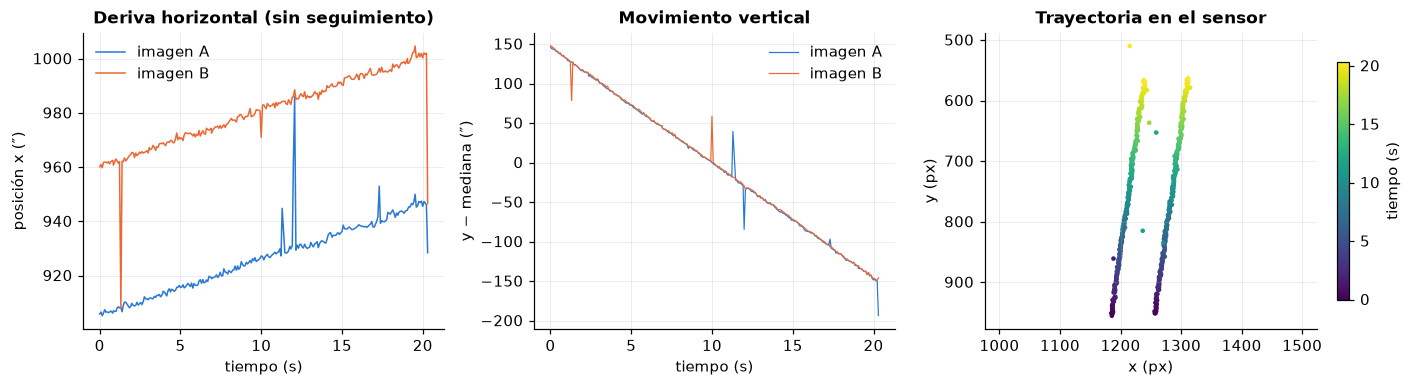

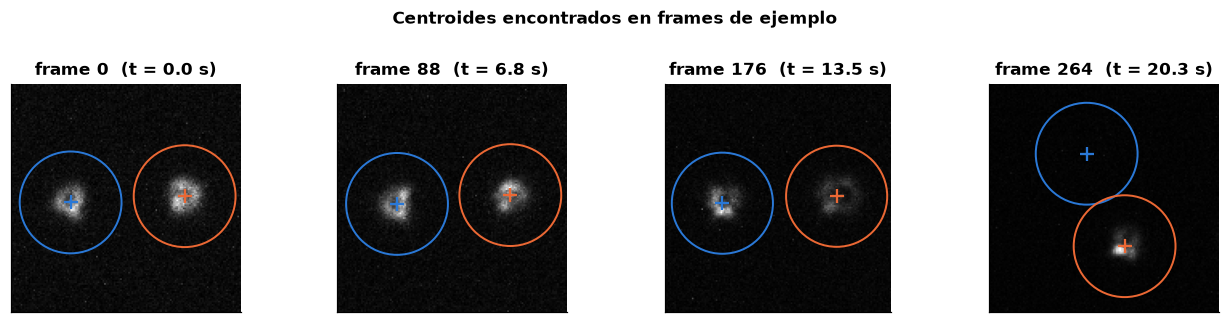

In [16]:
ok = df['estado'] == 'ok'
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={'width_ratios': [1, 1, 1.15]})
for n, c in (('A', C_A), ('B', C_B)):
    ax[0].plot(df.loc[ok, 't_s'], df.loc[ok, f'x{n}'] * ESCALA, color=c, lw=1, label=f'imagen {n}')
    ax[1].plot(df.loc[ok, 't_s'], (df.loc[ok, f'y{n}'] - df.loc[ok, f'y{n}'].median()) * ESCALA, color=c, lw=0.8, label=f'imagen {n}')
ax[0].set(xlabel='tiempo (s)', ylabel='posición x (″)', title='Deriva horizontal (sin seguimiento)')
ax[1].set(xlabel='tiempo (s)', ylabel='y − mediana (″)', title='Movimiento vertical')
ax[0].legend(); ax[1].legend()
sc = ax[2].scatter(df.loc[ok, 'xA'], df.loc[ok, 'yA'], c=df.loc[ok, 't_s'], s=4, cmap='viridis')
ax[2].scatter(df.loc[ok, 'xB'], df.loc[ok, 'yB'], c=df.loc[ok, 't_s'], s=4, cmap='viridis')
ax[2].set(xlabel='x (px)', ylabel='y (px)', title='Trayectoria en el sensor')
ax[2].set_aspect('equal', adjustable='datalim'); ax[2].invert_yaxis()
plt.colorbar(sc, ax=ax[2], label='tiempo (s)', shrink=0.8)
plt.tight_layout(); guardar(fig, '04_trayectoria'); plt.show()

ejemplos = np.linspace(0, ok[ok].index[-1], 4).astype(int)
fig, ax = plt.subplots(1, 4, figsize=(12, 2.8))
for a_, i in zip(ax, ejemplos):
    fila = df.loc[i]
    if fila['estado'] != 'ok':
        a_.set_title(f'frame {i}: {fila["estado"]}'); continue
    cxx, cyy = (fila['xA'] + fila['xB']) / 2, (fila['yA'] + fila['yB']) / 2
    w = ini['sep_px']
    sub = lector.leer(i, (max(int(cyy - w), 0), int(cyy + w), max(int(cxx - w), 0), int(cxx + w)))
    a_.imshow(sub, cmap='gray', origin='upper', extent=(max(int(cxx - w), 0) - 0.5, max(int(cxx - w), 0) + sub.shape[1] - 0.5,
                                                       max(int(cyy - w), 0) + sub.shape[0] - 0.5, max(int(cyy - w), 0) - 0.5))
    for n, c in (('A', C_A), ('B', C_B)):
        a_.add_patch(Circle((fila[f'x{n}'], fila[f'y{n}']), R_VENT, fill=False, ec=c, lw=1.3))
        a_.plot(fila[f'x{n}'], fila[f'y{n}'], '+', color=c, ms=9, mew=1.5)
    a_.set(title=f'frame {i}  (t = {fila["t_s"]:.1f} s)', xticks=[], yticks=[]); a_.grid(False)
plt.suptitle('Centroides encontrados en frames de ejemplo', fontweight='bold', y=1.03)
plt.tight_layout(); guardar(fig, '05_ejemplos_frames'); plt.show()

## 10. Control de calidad

Se descartan los frames que no sirven:
- **no_detectado / borde**: no se encontraron las dos imágenes, o la ventana sale del sensor (la estrella se está yendo).
- **saturado**: algún píxel llegó al máximo, y entonces el centroide no es confiable.
- **débil**: flujo < `FLUJO_MIN_REL` × mediana, por nubes o porque la estrella entra o sale del campo.
- **atípico**: separación o movimiento diferencial a más de `CORTE_ATIPICOS_SIGMA` sigmas robustas, por golpes al telescopio o rayos cósmicos.

estado
ok          191
saturado     48
borde        26
débil         5
atípico       1

Frames válidos: 191 de 271 (70 %)


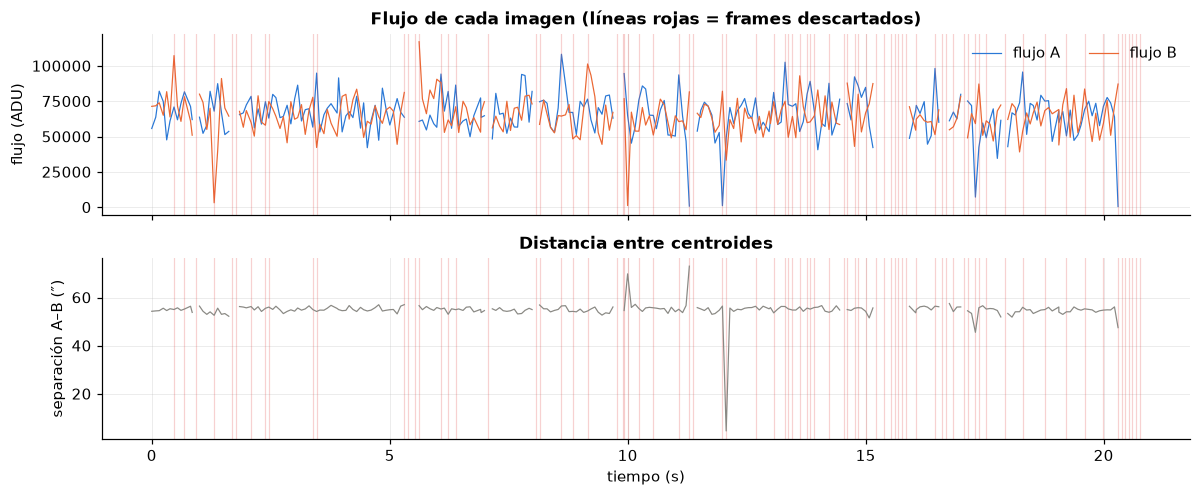

In [17]:
def proyectar(df, u):
    dx, dy = df['xB'] - df['xA'], df['yB'] - df['yA']
    df['l_px'] = dx * u[0] + dy * u[1]            # longitudinal: a lo largo de la línea base
    df['t_px'] = -dx * u[1] + dy * u[0]           # transversal: perpendicular
    df['ruido_l_px2'] = (df['varxA'] + df['varxB']) * u[0] ** 2 + (df['varyA'] + df['varyB']) * u[1] ** 2
    df['ruido_t_px2'] = (df['varxA'] + df['varxB']) * u[1] ** 2 + (df['varyA'] + df['varyB']) * u[0] ** 2
    return df

def control_calidad(df, lector):
    df = df.copy()
    ok = df['estado'] == 'ok'
    sat = ok & ((df['picoA'] >= 0.98 * lector.saturacion) | (df['picoB'] >= 0.98 * lector.saturacion))
    df.loc[sat, 'estado'] = 'saturado'
    ok = df['estado'] == 'ok'
    medF = np.nanmedian(df.loc[ok, ['flujoA', 'flujoB']].values)
    debil = ok & ((df['flujoA'] < FLUJO_MIN_REL * medF) | (df['flujoB'] < FLUJO_MIN_REL * medF))
    df.loc[debil, 'estado'] = 'débil'
    ok = df['estado'] == 'ok'
    dx, dy = (df.loc[ok, 'xB'] - df.loc[ok, 'xA']).median(), (df.loc[ok, 'yB'] - df.loc[ok, 'yA']).median()
    u = np.array([dx, dy]) / np.hypot(dx, dy)               # dirección de la línea base (mediana)
    df = proyectar(df, u)
    for col in ('l_px', 't_px'):
        ok = df['estado'] == 'ok'
        v = df.loc[ok, col]
        med, sig = v.median(), 1.4826 * np.median(np.abs(v - v.median()))
        malo = ok & (np.abs(df[col] - med) > CORTE_ATIPICOS_SIGMA * sig)
        df.loc[malo, 'estado'] = 'atípico'
    return df, u

df, U = control_calidad(df, lector)
ok = df['estado'] == 'ok'
resumen_estados = df['estado'].value_counts()
print(resumen_estados.to_string())
print(f"\nFrames válidos: {ok.sum()} de {len(df)} ({100*ok.mean():.0f} %)")

fig, ax = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True)
for n, c in (('A', C_A), ('B', C_B)):
    ax[0].plot(df['t_s'], df[f'flujo{n}'], color=c, lw=0.8, label=f'flujo {n}')
malos = df['estado'] != 'ok'
for a_ in ax:
    for t_ in df.loc[malos, 't_s']:
        a_.axvline(t_, color=C_MAL, alpha=0.25, lw=0.8)
ax[0].set(ylabel='flujo (ADU)', title='Flujo de cada imagen (líneas rojas = frames descartados)')
ax[0].legend(loc='upper right', ncol=2)
ax[1].plot(df['t_s'], np.hypot(df['xB'] - df['xA'], df['yB'] - df['yA']) * ESCALA, color=C_GRIS, lw=0.8)
ax[1].set(xlabel='tiempo (s)', ylabel='separación A–B (″)', title='Distancia entre centroides')
plt.tight_layout(); guardar(fig, '06_calidad'); plt.show()

## 11. Movimiento diferencial longitudinal y transversal

El vector A→B de cada frame se proyecta:
- **longitudinal $l$**: en la dirección de la línea que une los agujeros,
- **transversal $t$**: en la dirección perpendicular.

La turbulencia produce fluctuaciones aleatorias, aproximadamente gaussianas, alrededor del valor medio. Tokovinin muestra que la fluctuación longitudinal es mayor que la transversal; con tu máscara el cociente teórico de varianzas es $K_l/K_t \approx 1.41$.

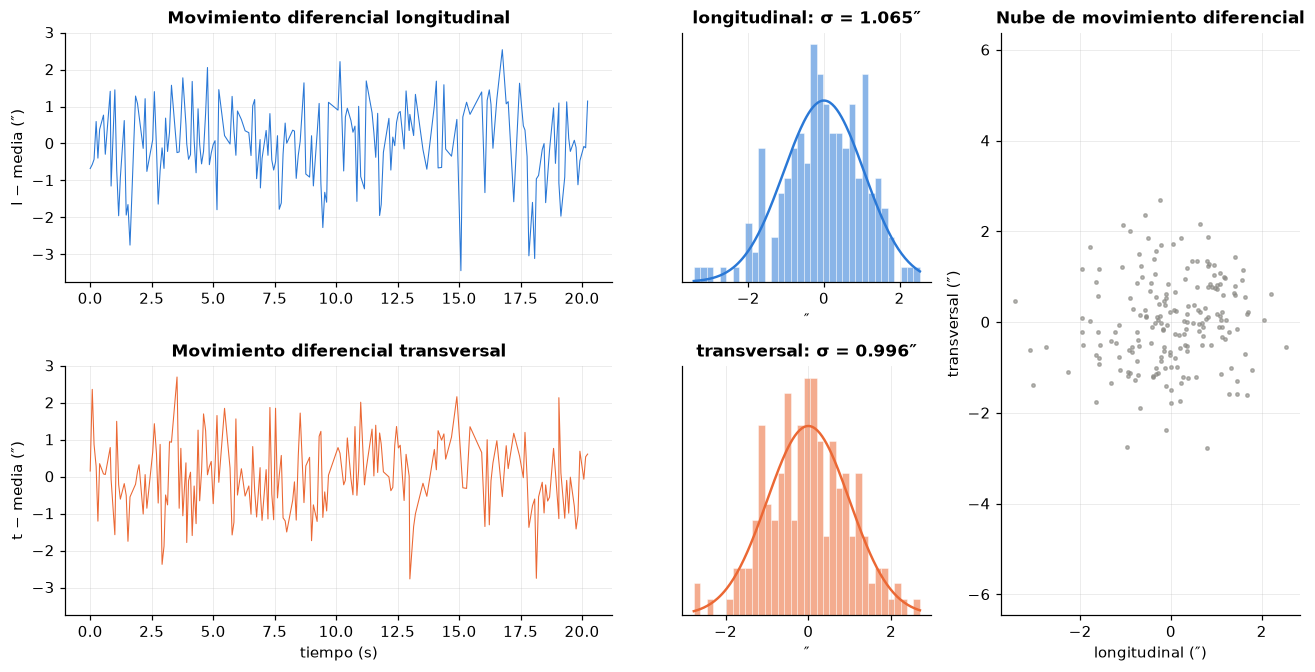

In [18]:
v = df.loc[ok]
l_as = (v['l_px'] - v['l_px'].mean()) * ESCALA
t_as = (v['t_px'] - v['t_px'].mean()) * ESCALA

fig = plt.figure(figsize=(12, 6.2))
g = fig.add_gridspec(2, 3, width_ratios=[2.2, 1, 1.2])
a1 = fig.add_subplot(g[0, 0]); a2 = fig.add_subplot(g[1, 0], sharex=a1, sharey=a1)
a1.plot(v['t_s'], l_as, color=C_L, lw=0.7); a1.set(ylabel='l − media (″)', title='Movimiento diferencial longitudinal')
a2.plot(v['t_s'], t_as, color=C_T, lw=0.7); a2.set(ylabel='t − media (″)', xlabel='tiempo (s)', title='Movimiento diferencial transversal')
for i_, (serie, c, nom) in enumerate([(l_as, C_L, 'longitudinal'), (t_as, C_T, 'transversal')]):
    a_ = fig.add_subplot(g[i_, 1])
    a_.hist(serie, bins=35, density=True, color=c, alpha=0.55, ec='white', lw=0.5)
    xx = np.linspace(serie.min(), serie.max(), 200); s_ = serie.std()
    a_.plot(xx, np.exp(-xx ** 2 / (2 * s_ ** 2)) / (s_ * np.sqrt(2 * np.pi)), color=c)
    a_.set(title=f'{nom}: σ = {s_:.3f}″', xlabel='″', yticks=[])
a3 = fig.add_subplot(g[:, 2])
a3.scatter(l_as, t_as, s=5, color=C_GRIS, alpha=0.6)
a3.set(xlabel='longitudinal (″)', ylabel='transversal (″)', title='Nube de movimiento diferencial')
a3.set_aspect('equal', adjustable='datalim')
plt.tight_layout(); guardar(fig, '07_movimiento_diferencial'); plt.show()

## 12. Ruido de centroide

Aunque la atmósfera estuviera perfectamente quieta, los centroides medidos "temblarían" por el ruido de fotones, el de lectura y el del cielo. Ese temblor **se suma** a la varianza medida y hace que el seeing parezca peor. Tokovinin (2002, sec. 3.1) indica que hay que restarlo.

Para cada imagen y cada frame se calcula la varianza de ruido del centroide con ventana:
$$\sigma^2_{x,\text{ruido}} = \frac{\sum_{\text{ventana}} (x_i - x_c)^2\,\left(\sigma^2_\text{fondo} + I_i/g\right)}{F^2}$$
En el movimiento diferencial se suman las contribuciones de las dos imágenes.

,varianza medida (″²),ruido (″²),ruido / medida (%)
longitudinal,1.13478,0.02309,2.03465
transversal,0.99181,0.02316,2.33489


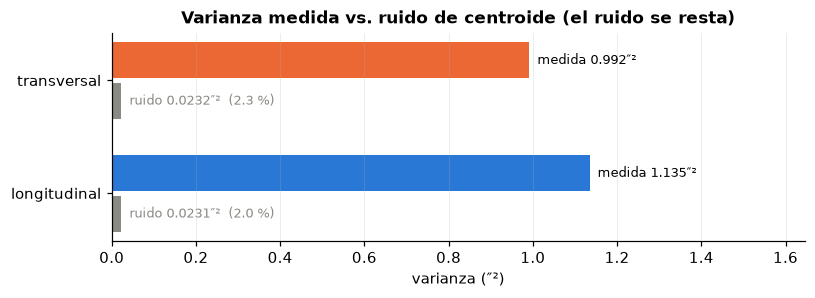

In [19]:
var_l_px2 = v['l_px'].var(ddof=1)
var_t_px2 = v['t_px'].var(ddof=1)
ruido_l_px2 = v['ruido_l_px2'].mean()
ruido_t_px2 = v['ruido_t_px2'].mean()

tabla_ruido = pd.DataFrame({
    'varianza medida (″²)': [var_l_px2 * ESCALA**2, var_t_px2 * ESCALA**2],
    'ruido (″²)': [ruido_l_px2 * ESCALA**2, ruido_t_px2 * ESCALA**2],
    'ruido / medida (%)': [100 * ruido_l_px2 / var_l_px2, 100 * ruido_t_px2 / var_t_px2],
}, index=['longitudinal', 'transversal'])
display(tabla_ruido.round(5))

fig, ax = plt.subplots(figsize=(7.5, 2.8))
y = np.arange(2)
med = tabla_ruido['varianza medida (″²)'].to_numpy(); rui = tabla_ruido['ruido (″²)'].to_numpy()
ax.barh(y + 0.18, med, height=0.32, color=[C_L, C_T])
ax.barh(y - 0.18, rui, height=0.32, color=C_GRIS)
for yi, m_, r_ in zip(y, med, rui):
    ax.text(m_, yi + 0.18, f'  medida {m_:.3f}″²', va='center', fontsize=8.5)
    ax.text(r_, yi - 0.18, f'  ruido {r_:.4f}″²  ({100*r_/m_:.1f} %)', va='center', fontsize=8.5, color=C_GRIS)
ax.set(yticks=y, yticklabels=tabla_ruido.index, xlabel='varianza (″²)', xlim=(0, med.max() * 1.45),
       title='Varianza medida vs. ruido de centroide (el ruido se resta)')
ax.grid(axis='y', visible=False)
plt.tight_layout(); guardar(fig, '08_ruido'); plt.show()
if (tabla_ruido['ruido / medida (%)'] > 30).any():
    print("⚠ El ruido es una fracción grande de la señal: usa una estrella más brillante, más ganancia o una exposición algo mayor.")

## 13. Cálculo del seeing

Para cada dirección se usa la varianza corregida (medida − ruido), convertida a radianes²:
$$r_0 = D\left[\frac{K\,(\lambda/D)^2}{\sigma^2}\right]^{3/5},\qquad \varepsilon = 0.98\,\frac{\lambda}{r_0}$$
El resultado final promedia la dirección longitudinal y la transversal. Si ambas dan valores parecidos, la medición es consistente. Una diferencia grande indica vibración del telescopio, viento o un efecto de la exposición (Sarazin & Roddier 1990).

Por comparación también se muestran las fórmulas clásicas de Sarazin & Roddier (1990), que usa el informe del CASLEO.

**Incertidumbre estadística.** Un video tiene un número finito de frames, y además los frames consecutivos se parecen entre sí. El número de muestras realmente independientes es $N_\text{ef} = N\,(1-\rho^2)/(1+\rho^2)$, con $\rho$ la correlación entre frames consecutivos. El error relativo del seeing es $\approx 0.6/\sqrt{N_\text{ef}}$, típicamente 3–5 % para 800 frames. A esto se suma el error sistemático del método (desenfoque, ~10 %; sección 18).

El seeing también se calcula por **bloques** de `TAMANO_BLOQUE` frames, para ver si fue estable durante el video.

,r₀ (cm),seeing (″),seeing Sarazin-Roddier (″),seeing sin restar ruido (″)
longitudinal,4.439,2.277,2.309,2.305
transversal,3.919,2.579,2.640,2.616
PROMEDIO,4.163,2.428,2.475,2.460


Seeing = 2.428 ± 0.106″ (error estadístico, N_efectivo = 187 frames independientes)
Cociente σ²_l/σ²_t medido = 1.15   (teoría 1.41)  ✔ consistente


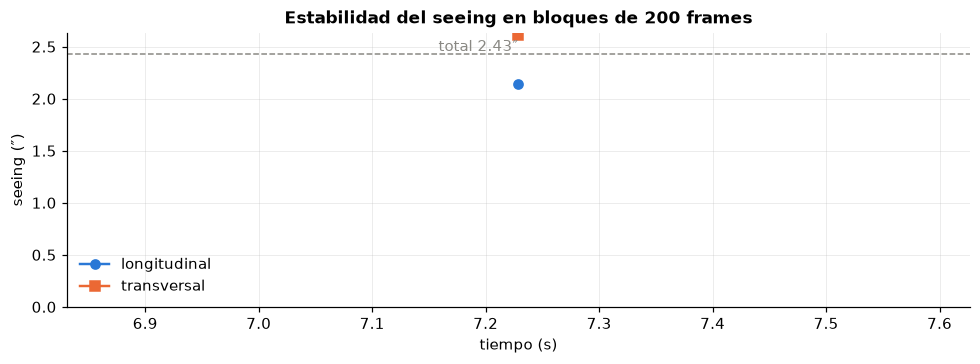

In [20]:
def autocorrelacion(df, col, max_lag=15):
    x = df[col].where(df['estado'] == 'ok').to_numpy(dtype=float)
    x = x - np.nanmean(x)
    out = []
    for k in range(max_lag + 1):
        a, b_ = (x, x) if k == 0 else (x[:-k], x[k:])
        m = np.isfinite(a) & np.isfinite(b_)
        out.append(np.corrcoef(a[m], b_[m])[0, 1] if k > 0 else 1.0)
    return np.array(out)

def n_efectivo(df):
    # Número de frames "independientes": los frames consecutivos están correlacionados (AR(1))
    rho = np.clip(np.nanmean([autocorrelacion(df, 'l_px', 1)[1], autocorrelacion(df, 't_px', 1)[1]]), 0, 0.99)
    n = int((df['estado'] == 'ok').sum())
    return n * (1 - rho ** 2) / (1 + rho ** 2), rho

def calcular_seeing(var_l_px2, var_t_px2, ruido_l_px2, ruido_t_px2, escala, Kl=KL, Kt=KT):
    out = {}
    for d, var, rui, K in (('l', var_l_px2, ruido_l_px2, Kl), ('t', var_t_px2, ruido_t_px2, Kt)):
        var_corr = (var - rui) * (escala / RAD2ARCSEC) ** 2
        if var_corr <= 0:
            out[f'r0_{d}'] = out[f'seeing_{d}'] = np.nan
        else:
            r0 = r0_desde_varianza(var_corr, K)
            out[f'r0_{d}'], out[f'seeing_{d}'] = r0, seeing_desde_r0(r0)
    out['seeing'] = np.nanmean([out['seeing_l'], out['seeing_t']])
    out['r0'] = 0.98 * LAMBDA_M / (out['seeing'] / RAD2ARCSEC)
    out['cociente_lt'] = (var_l_px2 - ruido_l_px2) / (var_t_px2 - ruido_t_px2)
    return out

S = calcular_seeing(var_l_px2, var_t_px2, ruido_l_px2, ruido_t_px2, ESCALA)
N_EFF, _ = n_efectivo(df)
S['err_seeing'] = S['seeing'] * 0.6 / np.sqrt(N_EFF)       # error estadístico (varianza con N_eff muestras)
S_sr = calcular_seeing(var_l_px2, var_t_px2, ruido_l_px2, ruido_t_px2, ESCALA, *coeficientes_sarazin_roddier(b))
S_sin_ruido = calcular_seeing(var_l_px2, var_t_px2, 0, 0, ESCALA)

tabla = pd.DataFrame({
    'r₀ (cm)': [S['r0_l'] * 100, S['r0_t'] * 100, S['r0'] * 100],
    'seeing (″)': [S['seeing_l'], S['seeing_t'], S['seeing']],
    'seeing Sarazin-Roddier (″)': [S_sr['seeing_l'], S_sr['seeing_t'], S_sr['seeing']],
    'seeing sin restar ruido (″)': [S_sin_ruido['seeing_l'], S_sin_ruido['seeing_t'], S_sin_ruido['seeing']],
}, index=['longitudinal', 'transversal', 'PROMEDIO'])
display(tabla.round(3))
print(f"Seeing = {S['seeing']:.3f} ± {S['err_seeing']:.3f}″ (error estadístico, N_efectivo = {N_EFF:.0f} frames independientes)")
print(f"Cociente σ²_l/σ²_t medido = {S['cociente_lt']:.2f}   (teoría {KL/KT:.2f})", end='  ')
print('✔ consistente' if 1.1 < S['cociente_lt'] < 1.8 else '⚠ revisa vibraciones/viento/rolling shutter')
if VERDAD is not None:
    err = 100 * (S['seeing'] / SIM['seeing_real'] - 1)
    print(f"\nSIMULACIÓN → seeing inyectado {SIM['seeing_real']:.3f}″, recuperado {S['seeing']:.3f}″  (diferencia {err:+.1f} %)")

# ---- por bloques ----
bloques = []
for k0 in range(0, len(df), TAMANO_BLOQUE):
    vb = df.iloc[k0:k0 + TAMANO_BLOQUE]; vb = vb[vb['estado'] == 'ok']
    if len(vb) < 50:
        continue
    sb = calcular_seeing(vb['l_px'].var(ddof=1), vb['t_px'].var(ddof=1),
                         vb['ruido_l_px2'].mean(), vb['ruido_t_px2'].mean(), ESCALA)
    bloques.append(dict(bloque=len(bloques) + 1, t_centro_s=vb['t_s'].mean(), n_validos=len(vb),
                        seeing_l=sb['seeing_l'], seeing_t=sb['seeing_t'], seeing=sb['seeing']))
bloques = pd.DataFrame(bloques)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(bloques['t_centro_s'], bloques['seeing_l'], 'o-', color=C_L, label='longitudinal', ms=6)
ax.plot(bloques['t_centro_s'], bloques['seeing_t'], 's-', color=C_T, label='transversal', ms=6)
ax.axhline(S['seeing'], color=C_GRIS, ls='--', lw=1)
ax.text(bloques['t_centro_s'].max(), S['seeing'], f"  total {S['seeing']:.2f}″", va='bottom', ha='right', color=C_GRIS)
ax.set(xlabel='tiempo (s)', ylabel='seeing (″)', title=f'Estabilidad del seeing en bloques de {TAMANO_BLOQUE} frames', ylim=(0, None))
ax.legend(loc='lower left'); plt.tight_layout(); guardar(fig, '09_bloques'); plt.show()

## 14. Corrección al cenit

La altura de la estrella se toma de `ALTITUD_DEG`. Si la dejaste en `None`, se calcula a partir de las coordenadas de la estrella, del sitio y de la hora UTC del video:
$$\sin h = \sin\varphi\sin\delta + \cos\varphi\cos\delta\cos H$$
Luego:
$$z = 90^\circ - h,\qquad \varepsilon_0 = \varepsilon\,(\cos z)^{3/5},\qquad r_{0,\text{cenit}} = r_0\,(\cos z)^{-3/5}$$
La corrección es confiable para alturas mayores a ~30° (masa de aire < 2).

In [21]:
def altitud_estrella(ar_h, dec_deg, lat_deg, lon_deg, fecha_utc):
    jd = (fecha_utc - dt.datetime(2000, 1, 1, 12)).total_seconds() / 86400.0 + 2451545.0
    gmst = (18.697374558 + 24.06570982441908 * (jd - 2451545.0)) % 24
    H = np.radians(((gmst + lon_deg / 15.0 - ar_h) % 24) * 15.0)
    phi, dec = np.radians(lat_deg), np.radians(dec_deg)
    return float(np.degrees(np.arcsin(np.sin(phi) * np.sin(dec) + np.cos(phi) * np.cos(dec) * np.cos(H))))

def obtener_altitud(lector):
    if ALTITUD_DEG is not None:
        return float(ALTITUD_DEG), 'dada en la configuración'
    if None not in (ESTRELLA_AR_HORAS, ESTRELLA_DEC_DEG, SITIO_LAT_DEG, SITIO_LON_DEG) and lector.fecha_utc:
        return altitud_estrella(ESTRELLA_AR_HORAS, ESTRELLA_DEC_DEG, SITIO_LAT_DEG, SITIO_LON_DEG, lector.fecha_utc), \
               f'calculada para {lector.fecha_utc:%Y-%m-%d %H:%M:%S} UTC'
    return np.nan, 'desconocida: define ALTITUD_DEG o las coordenadas'

def corregir_cenit(S, altitud):
    z = np.radians(90 - altitud)
    f = np.cos(z) ** 0.6
    return dict(altitud_deg=altitud, z_deg=90 - altitud, masa_aire=1 / np.cos(z),
                seeing_cenit=S['seeing'] * f, seeing_l_cenit=S['seeing_l'] * f, seeing_t_cenit=S['seeing_t'] * f,
                r0_cenit=S['r0'] / f)

ALT, origen_alt = obtener_altitud(lector)
Z = corregir_cenit(S, ALT)
print(f"Altura de la estrella: {ALT:.1f}° ({origen_alt})  →  z = {Z['z_deg']:.1f}°, masa de aire {Z['masa_aire']:.2f}")
print(f"Seeing en la línea de visión : {S['seeing']:.2f}″   (r₀ = {S['r0']*100:.1f} cm)")
print(f"Seeing corregido al cenit    : {Z['seeing_cenit']:.2f}″   (r₀ = {Z['r0_cenit']*100:.1f} cm)")
if ALT < 30:
    print("⚠ Altura < 30°: la corrección al cenit es poco confiable. Observa estrellas más altas.")

Altura de la estrella: 32.5° (dada en la configuración)  →  z = 57.5°, masa de aire 1.86
Seeing en la línea de visión : 2.43″   (r₀ = 4.2 cm)
Seeing corregido al cenit    : 1.67″   (r₀ = 6.0 cm)


## 15. Diagnóstico del tiempo de exposición

Durante una exposición el viento arrastra la turbulencia, la imagen se "promedia" y el movimiento medido **disminuye**: el seeing sale **mejor** de lo real (Tokovinin 2002, sec. 3.2). Por eso se usan exposiciones de ≤ 5–10 ms.

Tu video continuo permite un diagnóstico sencillo (idea de Kornilov & Safonov 2011): la **autocorrelación** del movimiento diferencial entre frames consecutivos.
- Si la correlación al primer desfase (Δt ≈ 17 ms) es **alta** (> 0.5), la turbulencia cambia despacio comparada con el intervalo entre frames, y una exposición de pocos ms la congela bien.
- Si es **baja** (< 0.2), la turbulencia es rápida (viento fuerte en altura) y conviene acortar la exposición.

Es una regla práctica, no una corrección cuantitativa.

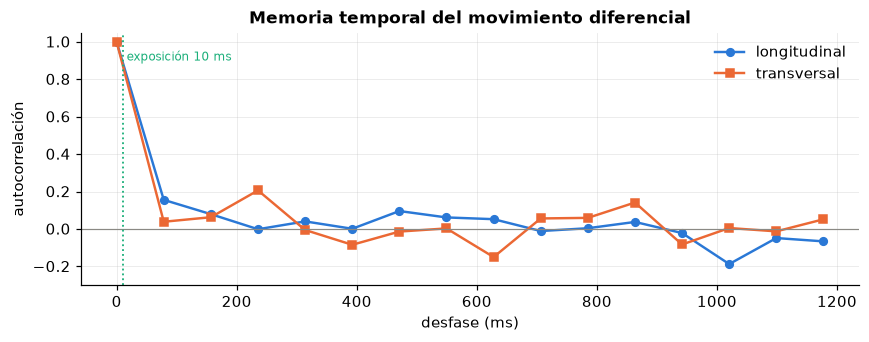

Correlación a 78.5 ms: 0.10  →  turbulencia rápida: acorta la exposición; el seeing podría estar subestimado


In [22]:
dt_frame = np.median(np.diff(lector.tiempos)) * 1000
ac_l, ac_t = autocorrelacion(df, 'l_px'), autocorrelacion(df, 't_px')
lags = np.arange(len(ac_l)) * dt_frame
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(lags, ac_l, 'o-', color=C_L, label='longitudinal', ms=5)
ax.plot(lags, ac_t, 's-', color=C_T, label='transversal', ms=5)
ax.axhline(0, color=C_GRIS, lw=0.8)
ax.axvline(EXPOSICION_MS, color=C_3, ls=':', lw=1.2)
ax.text(EXPOSICION_MS, 0.9, f' exposición {EXPOSICION_MS:g} ms', color=C_3, fontsize=8)
ax.set(xlabel='desfase (ms)', ylabel='autocorrelación', title='Memoria temporal del movimiento diferencial', ylim=(-0.3, 1.05))
ax.legend(); plt.tight_layout(); guardar(fig, '10_autocorrelacion'); plt.show()
rho1 = np.nanmean([ac_l[1], ac_t[1]])
print(f"Correlación a {dt_frame:.1f} ms: {rho1:.2f}  →  ", end='')
print('turbulencia lenta: exposición adecuada' if rho1 > 0.5 else
      'intermedia: la exposición de ≤5 ms es recomendable' if rho1 > 0.2 else
      'turbulencia rápida: acorta la exposición; el seeing podría estar subestimado')

## 16. Resumen y guardado de resultados

Se guardan en `CARPETA_RESULTADOS/<nombre_del_video>/`:
- `centroides_por_frame.csv`: posiciones, flujos, estado y movimiento diferencial de cada frame,
- `seeing_por_bloques.csv`,
- `resumen.json`: todos los parámetros y resultados del video,
- `figuras/*.png`: todas las gráficas.

Además se agrega (o actualiza) una fila en `CARPETA_RESULTADOS/registro_seeing.csv`, una tabla con **un renglón por video** para comparar videos y noches.

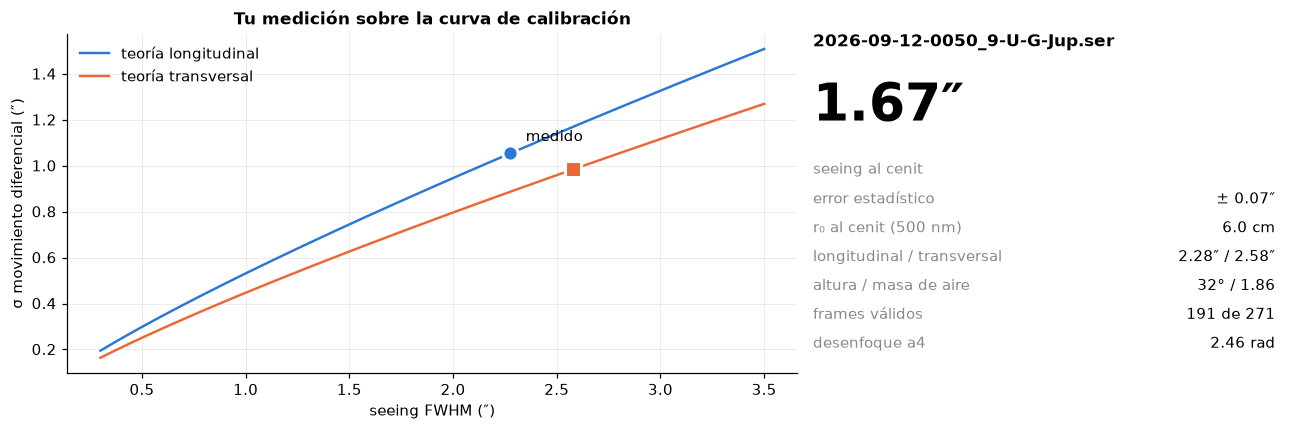

Resultados guardados en: resultados_seeing\2026-09-12-0050_9-U-G-Jup/
Registro de todos los videos: resultados_seeing\registro_seeing.csv


,valor
video,2026-09-12-0050_9-U-G-Jup.ser
fecha_utc,2026-09-12 00:50:56.717000
estrella,Alphecca
frames_total,271
frames_validos,191
fps,13.0
exposicion_ms,10.0
escala_arcsec_px,0.764
D_m,0.06
B_m,0.175


In [23]:
def armar_resumen(lector, ini, R, df, S, Z, rho1):
    ok = df['estado'] == 'ok'
    a4, dz = desenfoque_rad(ini['sep_px'], lector.k)
    return {
        'video': Path(lector.ruta).name, 'fecha_utc': str(lector.fecha_utc), 'estrella': NOMBRE_ESTRELLA,
        'frames_total': int(len(df)), 'frames_validos': int(ok.sum()),
        'fps': round((lector.n_frames - 1) / (lector.tiempos[-1] - lector.tiempos[0]), 2),
        'exposicion_ms': EXPOSICION_MS, 'escala_arcsec_px': round(ESCALA_NATIVA * lector.k, 4),
        'D_m': D_AGUJERO_M, 'B_m': B_SEPARACION_M, 'lambda_nm': LAMBDA_M * 1e9,
        'separacion_px': round(ini['sep_px'], 2), 'desenfoque_rad': round(a4, 3), 'ventana_px': round(R, 2),
        'var_l_arcsec2': df.loc[ok, 'l_px'].var(ddof=1) * (ESCALA_NATIVA * lector.k) ** 2,
        'var_t_arcsec2': df.loc[ok, 't_px'].var(ddof=1) * (ESCALA_NATIVA * lector.k) ** 2,
        'ruido_l_arcsec2': df.loc[ok, 'ruido_l_px2'].mean() * (ESCALA_NATIVA * lector.k) ** 2,
        'ruido_t_arcsec2': df.loc[ok, 'ruido_t_px2'].mean() * (ESCALA_NATIVA * lector.k) ** 2,
        'cociente_lt': S['cociente_lt'], 'r0_l_cm': S['r0_l'] * 100, 'r0_t_cm': S['r0_t'] * 100,
        'seeing_l': S['seeing_l'], 'seeing_t': S['seeing_t'], 'seeing': S['seeing'],
        'err_seeing': S.get('err_seeing', np.nan), 'r0_cm': S['r0'] * 100,
        'altitud_deg': Z['altitud_deg'], 'masa_aire': Z['masa_aire'],
        'seeing_cenit': Z['seeing_cenit'], 'r0_cenit_cm': Z['r0_cenit'] * 100, 'autocorr_lag1': rho1,
    }

def guardar_resultados(resumen, df, bloques, carpeta):
    carpeta = Path(carpeta); carpeta.mkdir(parents=True, exist_ok=True)
    df.to_csv(carpeta / 'centroides_por_frame.csv', index=False)
    if bloques is not None and len(bloques):
        bloques.to_csv(carpeta / 'seeing_por_bloques.csv', index=False)
    limpio = {k: (None if isinstance(v, float) and not np.isfinite(v) else (float(v) if isinstance(v, (np.floating,)) else v))
              for k, v in resumen.items()}
    with open(carpeta / 'resumen.json', 'w', encoding='utf-8') as f:
        json.dump(limpio, f, indent=2, ensure_ascii=False)
    reg = Path(CARPETA_RESULTADOS) / 'registro_seeing.csv'
    fila = pd.DataFrame([resumen])
    if reg.exists():
        viejo = pd.read_csv(reg)
        fila = pd.concat([viejo[viejo['video'] != resumen['video']], fila], ignore_index=True)
    fila.to_csv(reg, index=False)
    return reg

RESUMEN = armar_resumen(lector, ini, R_VENT, df, S, Z, rho1)

# ---- figura resumen ----
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1.5, 1]})
s = np.linspace(0.3, 3.5, 200)
ax[0].plot(s, sigma_diferencial_arcsec(s, KL), color=C_L, label='teoría longitudinal')
ax[0].plot(s, sigma_diferencial_arcsec(s, KT), color=C_T, label='teoría transversal')
sl = np.sqrt(RESUMEN['var_l_arcsec2'] - RESUMEN['ruido_l_arcsec2'])
st = np.sqrt(RESUMEN['var_t_arcsec2'] - RESUMEN['ruido_t_arcsec2'])
ax[0].plot(S['seeing_l'], sl, 'o', color=C_L, ms=10, mec='white', mew=2)
ax[0].plot(S['seeing_t'], st, 's', color=C_T, ms=10, mec='white', mew=2)
ax[0].annotate('medido', (S['seeing_l'], sl), xytext=(10, 8), textcoords='offset points')
ax[0].set(xlabel='seeing FWHM (″)', ylabel='σ movimiento diferencial (″)', title='Tu medición sobre la curva de calibración')
ax[0].legend(loc='upper left')
ax[1].axis('off')
lineas = [
    ('Seeing (línea de visión)', f"{S['seeing']:.2f}″"),
    ('Seeing corregido al cenit', f"{Z['seeing_cenit']:.2f}″"),
    ('error estadístico', f"± {S['err_seeing']*Z['seeing_cenit']/S['seeing']:.2f}″"),
    ('r₀ al cenit (500 nm)', f"{Z['r0_cenit']*100:.1f} cm"),
    ('longitudinal / transversal', f"{S['seeing_l']:.2f}″ / {S['seeing_t']:.2f}″"),
    ('altura / masa de aire', f"{ALT:.0f}° / {Z['masa_aire']:.2f}"),
    ('frames válidos', f"{RESUMEN['frames_validos']} de {RESUMEN['frames_total']}"),
    ('desenfoque a4', f"{RESUMEN['desenfoque_rad']:.2f} rad"),
]
ax[1].text(0, 1, RESUMEN['video'], fontsize=11, fontweight='bold', va='top', transform=ax[1].transAxes)
ax[1].text(0, 0.86, f"{Z['seeing_cenit']:.2f}″", fontsize=34, fontweight='bold', va='top', transform=ax[1].transAxes)
ax[1].text(0, 0.62, 'seeing al cenit', color=C_GRIS, va='top', transform=ax[1].transAxes)
for j, (k_, val) in enumerate(lineas[2:]):
    ax[1].text(0, 0.50 - j * 0.085, k_, color=C_GRIS, transform=ax[1].transAxes)
    ax[1].text(0.95, 0.50 - j * 0.085, val, ha='right', transform=ax[1].transAxes)
plt.tight_layout(); guardar(fig, '11_resumen'); plt.show()

reg = guardar_resultados(RESUMEN, df, bloques, CARPETA)
print(f"Resultados guardados en: {CARPETA}/")
print(f"Registro de todos los videos: {reg}")
pd.Series(RESUMEN).to_frame('valor')

## 17. Procesar varios videos de una noche

Cuando ya confíes en el análisis, pon todos los `.ser` de una noche en una carpeta y ejecuta esta sección. Corre el mismo análisis **sin gráficas intermedias**, guarda los resultados de cada video y al final grafica la evolución del seeing durante la noche.

Para que la corrección al cenit sea automática en cada video, define en la sección 3 las coordenadas de la estrella y del sitio y deja `ALTITUD_DEG = None`.

In [24]:
CARPETA_LOTE = None          # p.ej. "videos/2026-10-10"   (None = no hacer nada)

def analizar_video(ruta):
    global ESCALA
    leer_txt_firecapture(ruta)
    lec = LectorSER(ruta)
    ESCALA = ESCALA_NATIVA * lec.k
    ini_ = inicializar(lec)
    lamD = LAMBDA_D_ARCSEC / ESCALA
    R_ = RADIO_VENTANA_PX or min(0.45 * ini_['sep_px'], max(2.5 * lamD, 2.5 * ini_['rms_px']))
    d_ = medir_centroides(lec, ini_, R_, verbose=False)
    d_, _ = control_calidad(d_, lec)
    v_ = d_[d_['estado'] == 'ok']
    S_ = calcular_seeing(v_['l_px'].var(ddof=1), v_['t_px'].var(ddof=1),
                         v_['ruido_l_px2'].mean(), v_['ruido_t_px2'].mean(), ESCALA)
    S_['err_seeing'] = S_['seeing'] * 0.6 / np.sqrt(n_efectivo(d_)[0])
    alt_, _ = obtener_altitud(lec)
    Z_ = corregir_cenit(S_, alt_)
    rho_ = np.nanmean([autocorrelacion(d_, 'l_px', 1)[1], autocorrelacion(d_, 't_px', 1)[1]])
    res_ = armar_resumen(lec, ini_, R_, d_, S_, Z_, rho_)
    guardar_resultados(res_, d_, None, Path(CARPETA_RESULTADOS) / Path(ruta).stem)
    return res_

if CARPETA_LOTE:
    videos = sorted(Path(CARPETA_LOTE).glob('*.ser'))
    print(f"{len(videos)} videos encontrados")
    lote = []
    for ruta in videos:
        try:
            r_ = analizar_video(ruta); lote.append(r_)
            print(f"  {ruta.name}: seeing {r_['seeing']:.2f}″, al cenit {r_['seeing_cenit']:.2f}″")
        except Exception as e:
            print(f"  {ruta.name}: ERROR → {e}")
    lote = pd.DataFrame(lote)
    if len(lote):
        lote['hora'] = pd.to_datetime(lote['fecha_utc'], errors='coerce')
        fig, ax = plt.subplots(figsize=(9, 3.4))
        ax.plot(lote['hora'], lote['seeing_cenit'], 'o-', color=C_A)
        ax.axhline(lote['seeing_cenit'].median(), color=C_GRIS, ls='--', lw=1)
        ax.set(xlabel='hora UTC', ylabel='seeing al cenit (″)', title=f"Seeing durante la noche (mediana {lote['seeing_cenit'].median():.2f}″)")
        fig.autofmt_xdate(); plt.tight_layout(); plt.show()
        display(lote[['video', 'fecha_utc', 'frames_validos', 'seeing', 'seeing_cenit', 'r0_cenit_cm', 'cociente_lt']].round(3))
else:
    print("Define CARPETA_LOTE para procesar varios videos.")

Define CARPETA_LOTE para procesar varios videos.


## 18. Limitaciones y recomendaciones de captura

**Sobre el método sin cuña**
- El desenfoque necesario para separar las imágenes introduce un **sesgo** (Tokovinin & Kornilov 2007): con $a_4 > 0.8$ rad el seeing siempre sale sobreestimado, y aun con desenfoques menores el error puede ser de ±10 %. Desenfoca **lo mínimo** para que las imágenes no se toquen y usa **siempre el mismo desenfoque**, para que las noches sean comparables entre sí.
- Para tener una referencia absoluta, compara algunas noches con el FWHM de imágenes **enfocadas** sin máscara (exposición de ~1 s), o con un DIMM profesional si tienes acceso a sus datos.

**Parámetros sugeridos en FireCapture**
| Parámetro | Valor sugerido | Por qué |
|---|---|---|
| Exposición | 2–5 ms (máx. 10 ms) | congelar la turbulencia (CASLEO usa 4 ms) |
| Ganancia | la necesaria para un pico de 40–70 % del máximo | buena señal sin saturar; anota el valor |
| Formato | SER, 16 bits (o 8 bits si la señal es baja) | sin compresión |
| ROI | ancho suficiente para la deriva (≈ 15″ × cos δ por segundo; en 15 s ≈ 200″·cos δ ≈ 600 px) | más fps y archivos más pequeños |
| Duración | 10–15 s (~600–900 frames) | estadística suficiente |
| Debayer | **apagado** (guardar crudo) | el notebook hace el superpixel |

**Buenas prácticas**
- Gira la máscara para que las dos imágenes queden en la **misma fila** del sensor (efecto rolling shutter).
- Estrellas brillantes (magnitud ≤ 2) y **altas** (> 40–50° de altura).
- Deja el telescopio aclimatarse ~1 h para reducir la turbulencia del tubo.
- Anota la exposición, la ganancia, la estrella y la hora de cada video. FireCapture guarda un `.txt` junto a cada `.ser` con esa información.